# 1. Tải và Khám phá Bộ dữ liệu

## 1.1. Giới thiệu bộ dữ liệu

**Adult Census Income** là bộ dữ liệu phân loại nhị phân dùng để dự đoán một cá nhân có thu nhập năm vượt quá 50.000 USD hay không, dựa trên các đặc trưng nhân khẩu học và công việc.

Bộ dữ liệu gồm cả đặc trưng số và đặc trưng phân loại, phù hợp để khảo sát quy trình **Exploratory Data Analysis (EDA)**, tiền xử lý dữ liệu và xây dựng các mô hình phân loại.

**Biến mục tiêu:** `income`, gồm hai lớp:
- `<=50K`: thu nhập không vượt quá 50.000 USD.
- `>50K`: thu nhập vượt quá 50.000 USD.

Notebook sử dụng dữ liệu từ **UCI Machine Learning Repository**.

## 1.2. Truy xuất dữ liệu và Metadata từ UCI

Dữ liệu được tải trực tiếp từ **UCI Machine Learning Repository** thông qua thư viện `ucimlrepo`. Bên cạnh dữ liệu, metadata cung cấp thông tin về nguồn, cấu trúc và các thuộc tính của bộ dữ liệu. Việc truy xuất trực tiếp giúp duy trì tính nhất quán giữa dữ liệu sử dụng và nguồn công bố.

In [ ]:
# Install the UCI dataset import package
%pip install -q ucimlrepo


In [ ]:
import pandas as pd
from ucimlrepo import fetch_ucirepo

# Fetch the Adult dataset directly from UCI
adult = fetch_ucirepo(id=2)

# Retrieve dataset features and target
X = adult.data.features
y = adult.data.targets

# Combine features and target into one DataFrame
df = pd.concat([X, y], axis=1)

# Convert missing-value markers ('?') to NaN
df = df.replace(r"^\s*\?\s*$", float("nan"), regex=True)

print("Dataset loaded successfully!")
print(f"Number of samples: {df.shape[0]:,}")
print(f"Number of columns: {df.shape[1]}")


Dataset loaded successfully!
Number of samples: 48,842
Number of columns: 15


In [ ]:
# Display dataset metadata
print("Dataset name:", adult.metadata.name)
print("UCI dataset ID:", adult.metadata.uci_id)
print("Number of instances:", adult.metadata.num_instances)
print("Number of features:", adult.metadata.num_features)
print("Target column:", adult.metadata.target_col)
print("Has missing values:", adult.metadata.has_missing_values)

# Display variable-level metadata
display(adult.variables)


Dataset name: Adult
UCI dataset ID: 2
Number of instances: 48842
Number of features: 14
Target column: ['income']
Has missing values: yes


,name,role,type,demographic,description,units,missing_values
0,age,Feature,Integer,Age,N/A,None,no
1,workclass,Feature,Categorical,Income,"Private, Self-emp-not-inc, Self-emp-inc, Feder...",None,yes
2,fnlwgt,Feature,Integer,None,None,None,no
3,education,Feature,Categorical,Education Level,"Bachelors, Some-college, 11th, HS-grad, Prof-...",None,no
4,education-num,Feature,Integer,Education Level,None,None,no
5,marital-status,Feature,Categorical,Other,"Married-civ-spouse, Divorced, Never-married, S...",None,no
6,occupation,Feature,Categorical,Other,"Tech-support, Craft-repair, Other-service, Sal...",None,yes
7,relationship,Feature,Categorical,Other,"Wife, Own-child, Husband, Not-in-family, Other...",None,no
8,race,Feature,Categorical,Race,"White, Asian-Pac-Islander, Amer-Indian-Eskimo,...",None,no
9,sex,Feature,Binary,Sex,"Female, Male.",None,no


In [ ]:
df.head()


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,39,State-gov,77516,Bachelors,13,Never-married,Adm-clerical,Not-in-family,White,Male,2174,0,40,United-States,<=50K
1,50,Self-emp-not-inc,83311,Bachelors,13,Married-civ-spouse,Exec-managerial,Husband,White,Male,0,0,13,United-States,<=50K
2,38,Private,215646,HS-grad,9,Divorced,Handlers-cleaners,Not-in-family,White,Male,0,0,40,United-States,<=50K
3,53,Private,234721,11th,7,Married-civ-spouse,Handlers-cleaners,Husband,Black,Male,0,0,40,United-States,<=50K
4,28,Private,338409,Bachelors,13,Married-civ-spouse,Prof-specialty,Wife,Black,Female,0,0,40,Cuba,<=50K


# 2. EDA Lần 1: Khảo sát Chất lượng và Làm sạch Dữ liệu

EDA Lần 1 được thực hiện trên dữ liệu ban đầu nhằm đánh giá chất lượng dữ liệu trước khi chia tập. Các nội dung chính gồm:
1. Khảo sát kích thước, kiểu dữ liệu và cấu trúc các thuộc tính.
2. Thống kê Missing Values, bao gồm số lượng và tỷ lệ thiếu theo từng cột.
3. Kiểm tra các bản ghi trùng lặp và một số giá trị không hợp lệ theo logic dữ liệu.
4. Chuẩn hóa nhãn mục tiêu và loại bỏ các quan sát có Missing Values.

Việc làm sạch Missing Values được thực hiện trước khi chia Train/Validation/Test theo phạm vi phân tích của notebook. Các phân tích chuyên sâu và quyết định học từ dữ liệu ở những bước tiếp theo chỉ sử dụng tập Train.

## 2.1. Cấu trúc và Kích thước Dữ liệu

Khảo sát số lượng quan sát, số lượng đặc trưng, kiểu dữ liệu và số giá trị phân biệt của từng cột. Kết quả giúp xác định cấu trúc dữ liệu và lựa chọn các bước phân tích phù hợp.

In [ ]:
# Inspect dataset dimensions
n_samples, n_columns = df.shape
n_features = n_columns - 1  # Exclude target column

print(f"Number of samples: {n_samples:,}")
print(f"Number of input features: {n_features}")
print(f"Number of columns (including target): {n_columns}")

# Inspect column data types and unique counts
display(
    pd.DataFrame({
        "Column": df.columns,
        "Data Type": df.dtypes.astype(str).values,
        "Unique Values": df.nunique(dropna=True).values
    })
)


Number of samples: 48,842
Number of input features: 14
Number of columns (including target): 15


,Column,Data Type,Unique Values
0,age,int64,74
1,workclass,object,8
2,fnlwgt,int64,28523
3,education,object,16
4,education-num,int64,16
5,marital-status,object,7
6,occupation,object,14
7,relationship,object,6
8,race,object,5
9,sex,object,2


## 2.2. Phân tích Giá trị Thiếu (Missing Values)

Trong dữ liệu Adult Census Income, một số giá trị thiếu được biểu diễn bằng ký hiệu `?`. Các giá trị này đã được chuyển thành `NaN` khi nạp dữ liệu. Ta thống kê số lượng và tỷ lệ Missing Values theo từng đặc trưng, đồng thời xác định tỷ lệ quan sát có ít nhất một giá trị thiếu.

In [ ]:
import pandas as pd

# Count missing values in each column
missing_count = df.isnull().sum()

# Keep only columns that contain missing values
missing_summary = pd.DataFrame({
    "Missing Count": missing_count[missing_count > 0],
    "Missing Percentage (%)": (
        missing_count[missing_count > 0] / len(df) * 100
    ).round(2)
})

# Display the results
if missing_summary.empty:
    print("No missing values found in the dataset.")
else:
    missing_summary = missing_summary.sort_values(
        by="Missing Count", ascending=False
    )
    display(missing_summary)

    print(f"Total samples: {len(df):,}")
    print(f"Features with missing values: {len(missing_summary)}")


,Missing Count,Missing Percentage (%)
occupation,2809,5.75
workclass,2799,5.73
native-country,857,1.75


Total samples: 48,842
Features with missing values: 3


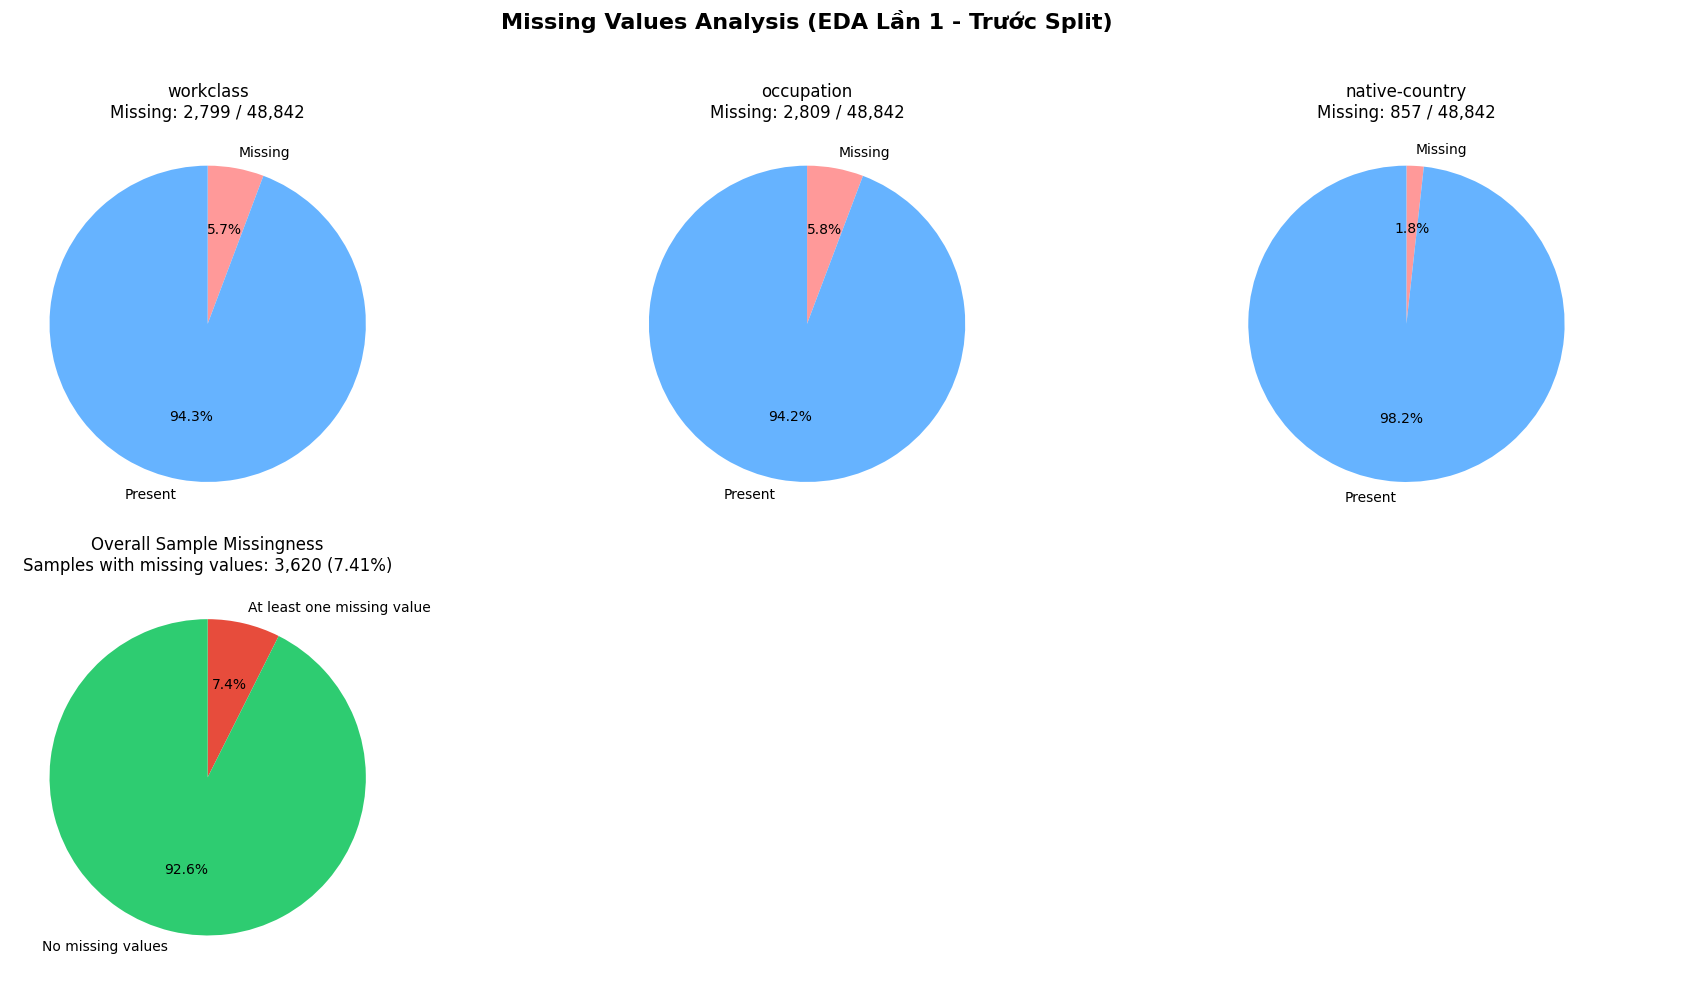

Chart saved to: /content/EDA_result/missing_values_analysis.png


In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path
import math

# Create output directory for EDA results
EDA_DIR = Path("EDA_result")
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Identify features containing missing values
missing_cols = df.columns[df.isnull().any()].tolist()

# Calculate samples with and without missing values
samples_with_missing = df.isnull().any(axis=1).sum()
samples_without_missing = len(df) - samples_with_missing

if not missing_cols:
    print("No missing values found. No pie charts were generated.")
else:
    n_plots = len(missing_cols) + 1  # Feature charts + overall chart
    n_cols = min(3, n_plots)
    n_rows = math.ceil(n_plots / n_cols)

    fig, axes = plt.subplots(
        n_rows,
        n_cols,
        figsize=(6 * n_cols, 5 * n_rows)
    )
    axes = axes.flatten() if hasattr(axes, "flatten") else [axes]

    # Plot missing vs. non-missing values for each feature
    for i, col in enumerate(missing_cols):
        n_missing = df[col].isnull().sum()
        n_present = len(df) - n_missing

        axes[i].pie(
            [n_missing, n_present],
            labels=["Missing", "Present"],
            autopct="%1.1f%%",
            startangle=90,
            counterclock=False,
            colors=["#ff9999", "#66b3ff"]
        )
        axes[i].set_title(
            f"{col}\nMissing: {n_missing:,} / {len(df):,}"
        )

    # Plot the overall proportion of samples with missing values
    overall_idx = len(missing_cols)
    axes[overall_idx].pie(
        [samples_with_missing, samples_without_missing],
        labels=["At least one missing value", "No missing values"],
        autopct="%1.1f%%",
        startangle=90,
        counterclock=False,
        colors=["#e74c3c", "#2ecc71"]
    )
    axes[overall_idx].set_title(
        "Overall Sample Missingness\n"
        f"Samples with missing values: {samples_with_missing:,} ({samples_with_missing / len(df) * 100:.2f}%)"
    )

    # Hide unused subplot axes
    for i in range(n_plots, len(axes)):
        axes[i].axis("off")

    fig.suptitle(
        "Missing Values Analysis (EDA Lần 1 - Trước Split)",
        fontsize=16,
        fontweight="bold"
    )
    plt.tight_layout(rect=[0, 0, 1, 0.96])

    output_path = EDA_DIR / "missing_values_analysis.png"
    fig.savefig(output_path, dpi=200, bbox_inches="tight")
    plt.show()
    plt.close(fig)

    print(f"Chart saved to: {output_path.resolve()}")


## 2.3. Kiểm tra Bản ghi Trùng lặp và Tính Hợp lệ

Bản ghi trùng lặp hoàn toàn có thể làm tăng mức độ đại diện của một số quan sát. Vì vậy, bước này thống kê số dòng trùng lặp và rà soát các giá trị vi phạm những ràng buộc logic cơ bản, chẳng hạn tuổi hoặc số giờ làm việc mang giá trị âm.

In [ ]:
# Count duplicated rows
duplicate_mask = df.duplicated()
n_duplicates = duplicate_mask.sum()
n_samples = len(df)

duplicate_percentage = (n_duplicates / n_samples * 100) if n_samples > 0 else 0

print(f"Total samples: {n_samples:,}")
print(f"Duplicate records: {n_duplicates:,}")
print(f"Duplicate percentage: {duplicate_percentage:.2f}%")
print(f"Unique records: {n_samples - n_duplicates:,}")

# Check validity constraints on numerical features
invalid_checks = {
    "age": df["age"] < 0,
    "fnlwgt": df["fnlwgt"] < 0,
    "education-num": df["education-num"] < 0,
    "capital-gain": df["capital-gain"] < 0,
    "capital-loss": df["capital-loss"] < 0,
    "hours-per-week": df["hours-per-week"] < 0,
}

invalid_summary = []
for col, mask in invalid_checks.items():
    cnt = int(mask.sum())
    invalid_summary.append({
        "Feature": col,
        "Invalid Count": cnt,
        "Invalid Percentage (%)": round(cnt / len(df) * 100, 4)
    })

display(pd.DataFrame(invalid_summary))


Total samples: 48,842
Duplicate records: 29
Duplicate percentage: 0.06%
Unique records: 48,813


,Feature,Invalid Count,Invalid Percentage (%)
0,age,0,0.0
1,fnlwgt,0,0.0
2,education-num,0,0.0
3,capital-gain,0,0.0
4,capital-loss,0,0.0
5,hours-per-week,0,0.0


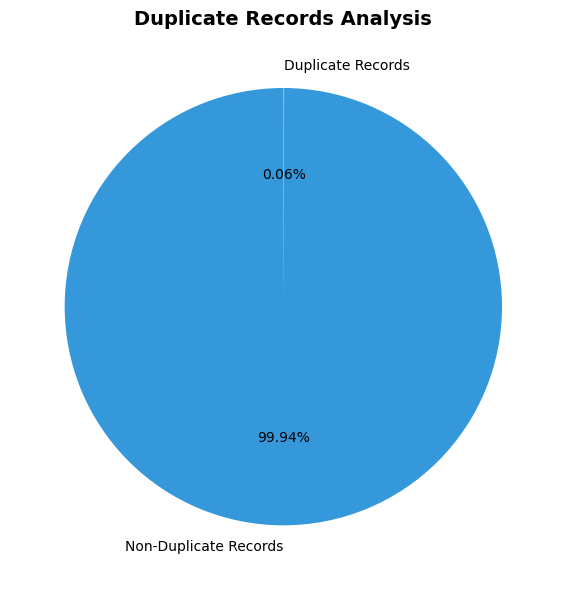

Chart saved to: /content/EDA_result/duplicate_records_analysis.png


In [ ]:
import matplotlib.pyplot as plt

# Visualize duplicate records
n_unique_records = n_samples - n_duplicates

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(
    [n_duplicates, n_unique_records],
    labels=["Duplicate Records", "Non-Duplicate Records"],
    autopct="%1.2f%%",
    startangle=90,
    counterclock=False,
    colors=["#f39c12", "#3498db"]
)
ax.set_title("Duplicate Records Analysis", fontsize=14, fontweight="bold")
plt.tight_layout()

output_path = EDA_DIR / "duplicate_records_analysis.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Chart saved to: {output_path.resolve()}")


## 2.4. Làm sạch Missing Values

Các quan sát chứa ít nhất một giá trị thiếu (`NaN`) được loại bỏ trước khi chia tập. Nhãn `income` đồng thời được chuẩn hóa bằng cách loại bỏ khoảng trắng và dấu chấm ở cuối nhãn, nhằm thống nhất định dạng giữa các phần dữ liệu của nguồn UCI.

In [ ]:
# Normalize target labels before cleaning and splitting
df["income"] = df["income"].str.strip().str.rstrip(".")

# Store dataset size before cleaning
n_before = len(df)

# Filter missing values across the entire dataset
df_cleaned = df.dropna().copy()

n_after = len(df_cleaned)
n_dropped = n_before - n_after

print("=" * 60)
print("KẾT QUẢ LỌC BỎ NULL TRÊN TOÀN BỘ DATASET (EDA LẦN 1)")
print("=" * 60)
print(f"Số lượng mẫu ban đầu:              {n_before:,}")
print(f"Số lượng mẫu bị lọc bỏ (có null):   {n_dropped:,} ({n_dropped / n_before * 100:.2f}%)")
print(f"Số lượng mẫu sạch hoàn chỉnh:      {n_after:,} ({n_after / n_before * 100:.2f}%)")
print(f"Số giá trị missing còn lại:        {df_cleaned.isnull().sum().sum()}")
print("=" * 60)

# Verify clean dataset target distribution
print("\nPhân phối nhãn mục tiêu sau khi lọc null:")
display(df_cleaned["income"].value_counts(normalize=True).to_frame("Tỷ lệ (%)").assign(
    Số_mẫu=df_cleaned["income"].value_counts()
))


KẾT QUẢ LỌC BỎ NULL TRÊN TOÀN BỘ DATASET (EDA LẦN 1)
Số lượng mẫu ban đầu:              48,842
Số lượng mẫu bị lọc bỏ (có null):   3,620 (7.41%)
Số lượng mẫu sạch hoàn chỉnh:      45,222 (92.59%)
Số giá trị missing còn lại:        0

Phân phối nhãn mục tiêu sau khi lọc null:


,Tỷ lệ (%),Số_mẫu
income,,
<=50K,0.752156,34014
>50K,0.247844,11208


# 3. Chia Dữ liệu thành Train, Validation và Test

Sau khi xử lý Missing Values, dữ liệu được chia thành ba tập độc lập theo tỷ lệ 70% / 15% / 15%:
- **Training Set:** dùng cho EDA chuyên sâu, huấn luyện mô hình và fit các bước tiền xử lý.
- **Validation Set:** dùng để theo dõi và so sánh mô hình trong quá trình phát triển.
- **Test Set:** được giữ riêng để đánh giá cuối cùng sau khi lựa chọn mô hình.

Sử dụng `stratify` để duy trì tỷ lệ các lớp mục tiêu giữa các tập. Để hạn chế **Data Leakage**, các thống kê phục vụ quyết định xử lý, `Encoder` và `Scaler` đều được fit trên Train; Validation và Test chỉ được transform bằng các tham số đã học từ Train.

In [ ]:
from sklearn.model_selection import train_test_split

# Separate features and target from the cleaned dataset
X = df_cleaned.drop(columns=["income"])
y = df_cleaned["income"]

# Split into training (70%) and temporary (30%) sets with stratification
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Split temporary set equally into validation (15%) and test (15%) sets
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Display split summary
split_summary = pd.DataFrame({
    "Tập dữ liệu": ["Training (Train)", "Validation (Val)", "Testing (Test)", "Tổng cộng"],
    "Số lượng mẫu": [len(X_train), len(X_val), len(X_test), len(df_cleaned)],
    "Tỷ lệ (%)": [
        f"{len(X_train) / len(df_cleaned) * 100:.2f}%",
        f"{len(X_val) / len(df_cleaned) * 100:.2f}%",
        f"{len(X_test) / len(df_cleaned) * 100:.2f}%",
        "100.00%"
    ]
})

display(split_summary)


,Tập dữ liệu,Số lượng mẫu,Tỷ lệ (%)
0,Training (Train),31655,70.00%
1,Validation (Val),6783,15.00%
2,Testing (Test),6784,15.00%
3,Tổng cộng,45222,100.00%


In [ ]:
# Verify stratified target distributions across splits
target_dist = pd.DataFrame({
    "Train (%)": (y_train.value_counts(normalize=True) * 100).round(2),
    "Validation (%)": (y_val.value_counts(normalize=True) * 100).round(2),
    "Test (%)": (y_test.value_counts(normalize=True) * 100).round(2)
})

print("Phân phối nhãn mục tiêu trên từng tập (Kiểm tra tính phân tầng Stratification):")
display(target_dist)


Phân phối nhãn mục tiêu trên từng tập (Kiểm tra tính phân tầng Stratification):


,Train (%),Validation (%),Test (%)
income,,,
<=50K,75.21,75.22,75.22
>50K,24.79,24.78,24.78


# 4. EDA Lần 2: Phân tích Chuyên sâu trên Training Set

EDA Lần 2 chỉ sử dụng `X_train` và `y_train`. Mục tiêu là hiểu phân phối dữ liệu, nhận diện quan sát ngoại lai, đánh giá mức độ liên hệ giữa đặc trưng và biến mục tiêu, từ đó đưa ra quyết định tiền xử lý có căn cứ.

Các nội dung gồm:
1. Phân tích `Class Imbalance` để lựa chọn cách đánh giá và thiết lập trọng số lớp khi phù hợp.
2. Khảo sát phân phối đơn biến (`Univariate Analysis`) và các giá trị ngoại lai (`Outliers`).
3. Phân tích quan hệ giữa các đặc trưng (`Feature-Feature Relationships`) để nhận diện thông tin trùng lặp.
4. Phân tích quan hệ giữa đặc trưng và `income` bằng tương quan, phân phối theo lớp và `Mutual Information`.
5. Chỉ loại bỏ quan sát hoặc đặc trưng khi kết quả phân tích cung cấp đủ căn cứ. Nếu không có đối tượng cần loại, dữ liệu được giữ nguyên.

## 4.1. Phân tích Mất cân bằng Lớp (Class Imbalance)

Thống kê số lượng và tỷ lệ của hai lớp `<=50K` và `>50K` trên Training Set. Tỷ lệ giữa lớp đa số và lớp thiểu số được sử dụng để cân nhắc các phương pháp xử lý mất cân bằng trong quá trình huấn luyện.

Phân bố lớp được cập nhật lại sau bước kiểm tra Outlier nếu Training Set có thay đổi; tỷ lệ cập nhật mới là giá trị được sử dụng khi huấn luyện mô hình.

,Class,Sample Count,Percentage (%)
0,<=50K (Low Income),23809,75.21
1,>50K (High Income),7846,24.79


Số lượng mẫu âm tính (<=50K): 23,809
Số lượng mẫu dương tính (>50K): 7,846
Tỷ lệ mất cân bằng (Negative / Positive): 3.03 : 1


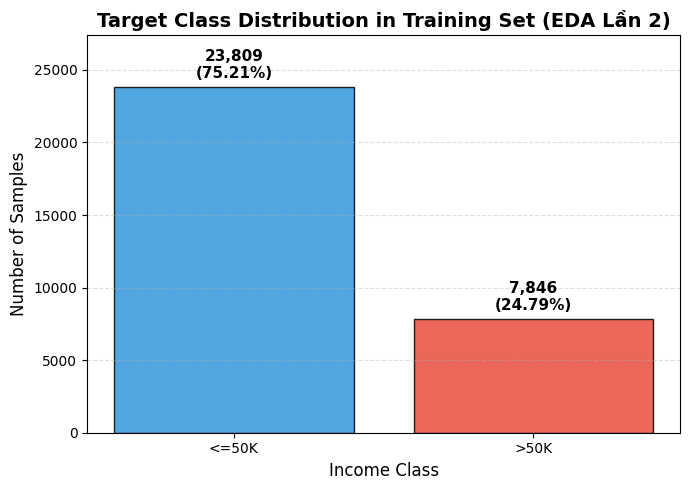

Biểu đồ đã được lưu tại: /content/EDA_result/target_class_distribution_train.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

EDA_DIR = Path("EDA_result")
EDA_DIR.mkdir(parents=True, exist_ok=True)

# Calculate class distribution in the training set
train_counts = y_train.value_counts()
train_percentages = y_train.value_counts(normalize=True) * 100

class_imbalance_df = pd.DataFrame({
    "Class": ["<=50K (Low Income)", ">50K (High Income)"],
    "Sample Count": [train_counts.get("<=50K", 0), train_counts.get(">50K", 0)],
    "Percentage (%)": [train_percentages.get("<=50K", 0), train_percentages.get(">50K", 0)]
})

neg_count = train_counts.get("<=50K", 0)
pos_count = train_counts.get(">50K", 0)
imbalance_ratio = neg_count / pos_count

display(class_imbalance_df.round(2))
print(f"Số lượng mẫu âm tính (<=50K): {neg_count:,}")
print(f"Số lượng mẫu dương tính (>50K): {pos_count:,}")
print(f"Tỷ lệ mất cân bằng (Negative / Positive): {imbalance_ratio:.2f} : 1")

# Visualize target class distribution
fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(
    ["<=50K", ">50K"],
    [neg_count, pos_count],
    color=["#3498db", "#e74c3c"],
    edgecolor="black",
    alpha=0.85
)

ax.set_title("Target Class Distribution in Training Set (EDA Lần 2)", fontsize=14, fontweight="bold")
ax.set_xlabel("Income Class", fontsize=12)
ax.set_ylabel("Number of Samples", fontsize=12)
ax.grid(axis="y", linestyle="--", alpha=0.4)

for bar, pct in zip(bars, class_imbalance_df["Percentage (%)"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 400,
        f"{int(bar.get_height()):,}\n({pct:.2f}%)",
        ha="center",
        va="bottom",
        fontsize=11,
        fontweight="bold"
    )

ax.set_ylim(0, max(neg_count, pos_count) * 1.15)
fig.tight_layout()

output_path = EDA_DIR / "target_class_distribution_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


### Nhận xét và Hướng xử lý Class Imbalance

Tỷ lệ giữa hai lớp cho thấy mức độ mất cân bằng của Training Set. Khi lớp `>50K` ít hơn đáng kể, mô hình có thể thiên về dự đoán lớp đa số; do đó Accuracy đơn lẻ chưa phản ánh đầy đủ chất lượng phân loại.

Tỷ lệ `imbalance_ratio` được sử dụng làm cơ sở thiết lập `scale_pos_weight` cho XGBoost và `pos_weight` cho hàm mất mát của MLP. Các mô hình khác được đánh giá trên cùng Validation/Test Set; khác biệt về cơ chế xử lý mất cân bằng sẽ được xem xét khi diễn giải kết quả. Các chỉ số Precision, Recall, F1-score của lớp `>50K` và ROC-AUC được báo cáo bên cạnh Accuracy.

## 4.2. Phân tích Phân phối Đặc trưng (Univariate Analysis)

Thống kê mô tả, Histogram và Boxplot được sử dụng để quan sát hình dạng phân phối, độ lệch (`Skewness`) và phạm vi giá trị của các đặc trưng số. Với đặc trưng phân loại, ta khảo sát số nhóm giá trị và tần suất xuất hiện. Kết quả là cơ sở để nhận diện những điểm cần kiểm tra sâu hơn, không mặc định rằng mọi điểm nằm ngoài Boxplot đều là dữ liệu sai.

In [ ]:
# Identify numerical features in X_train
numerical_features = X_train.select_dtypes(include="number").columns.tolist()

# Descriptive statistics including median and skewness
num_stats = X_train[numerical_features].describe().T
num_stats["median"] = X_train[numerical_features].median()
num_stats["skewness"] = X_train[numerical_features].skew()
num_stats = num_stats[
    ["count", "mean", "median", "std", "min", "25%", "50%", "75%", "max", "skewness"]
].round(2)

print("Thống kê mô tả các đặc trưng số trên tập Train:")
display(num_stats)


Thống kê mô tả các đặc trưng số trên tập Train:


,count,mean,median,std,min,25%,50%,75%,max,skewness
age,31655.0,38.58,37.0,13.21,17.0,28.0,37.0,47.0,90.0,0.53
fnlwgt,31655.0,190099.30,178322.0,105948.32,13769.0,117504.5,178322.0,238231.0,1490400.0,1.47
education-num,31655.0,10.12,10.0,2.56,1.0,9.0,10.0,13.0,16.0,-0.32
capital-gain,31655.0,1123.38,0.0,7613.14,0.0,0.0,0.0,0.0,99999.0,11.63
capital-loss,31655.0,89.79,0.0,407.20,0.0,0.0,0.0,0.0,4356.0,4.47
hours-per-week,31655.0,40.94,40.0,11.99,1.0,40.0,40.0,45.0,99.0,0.30


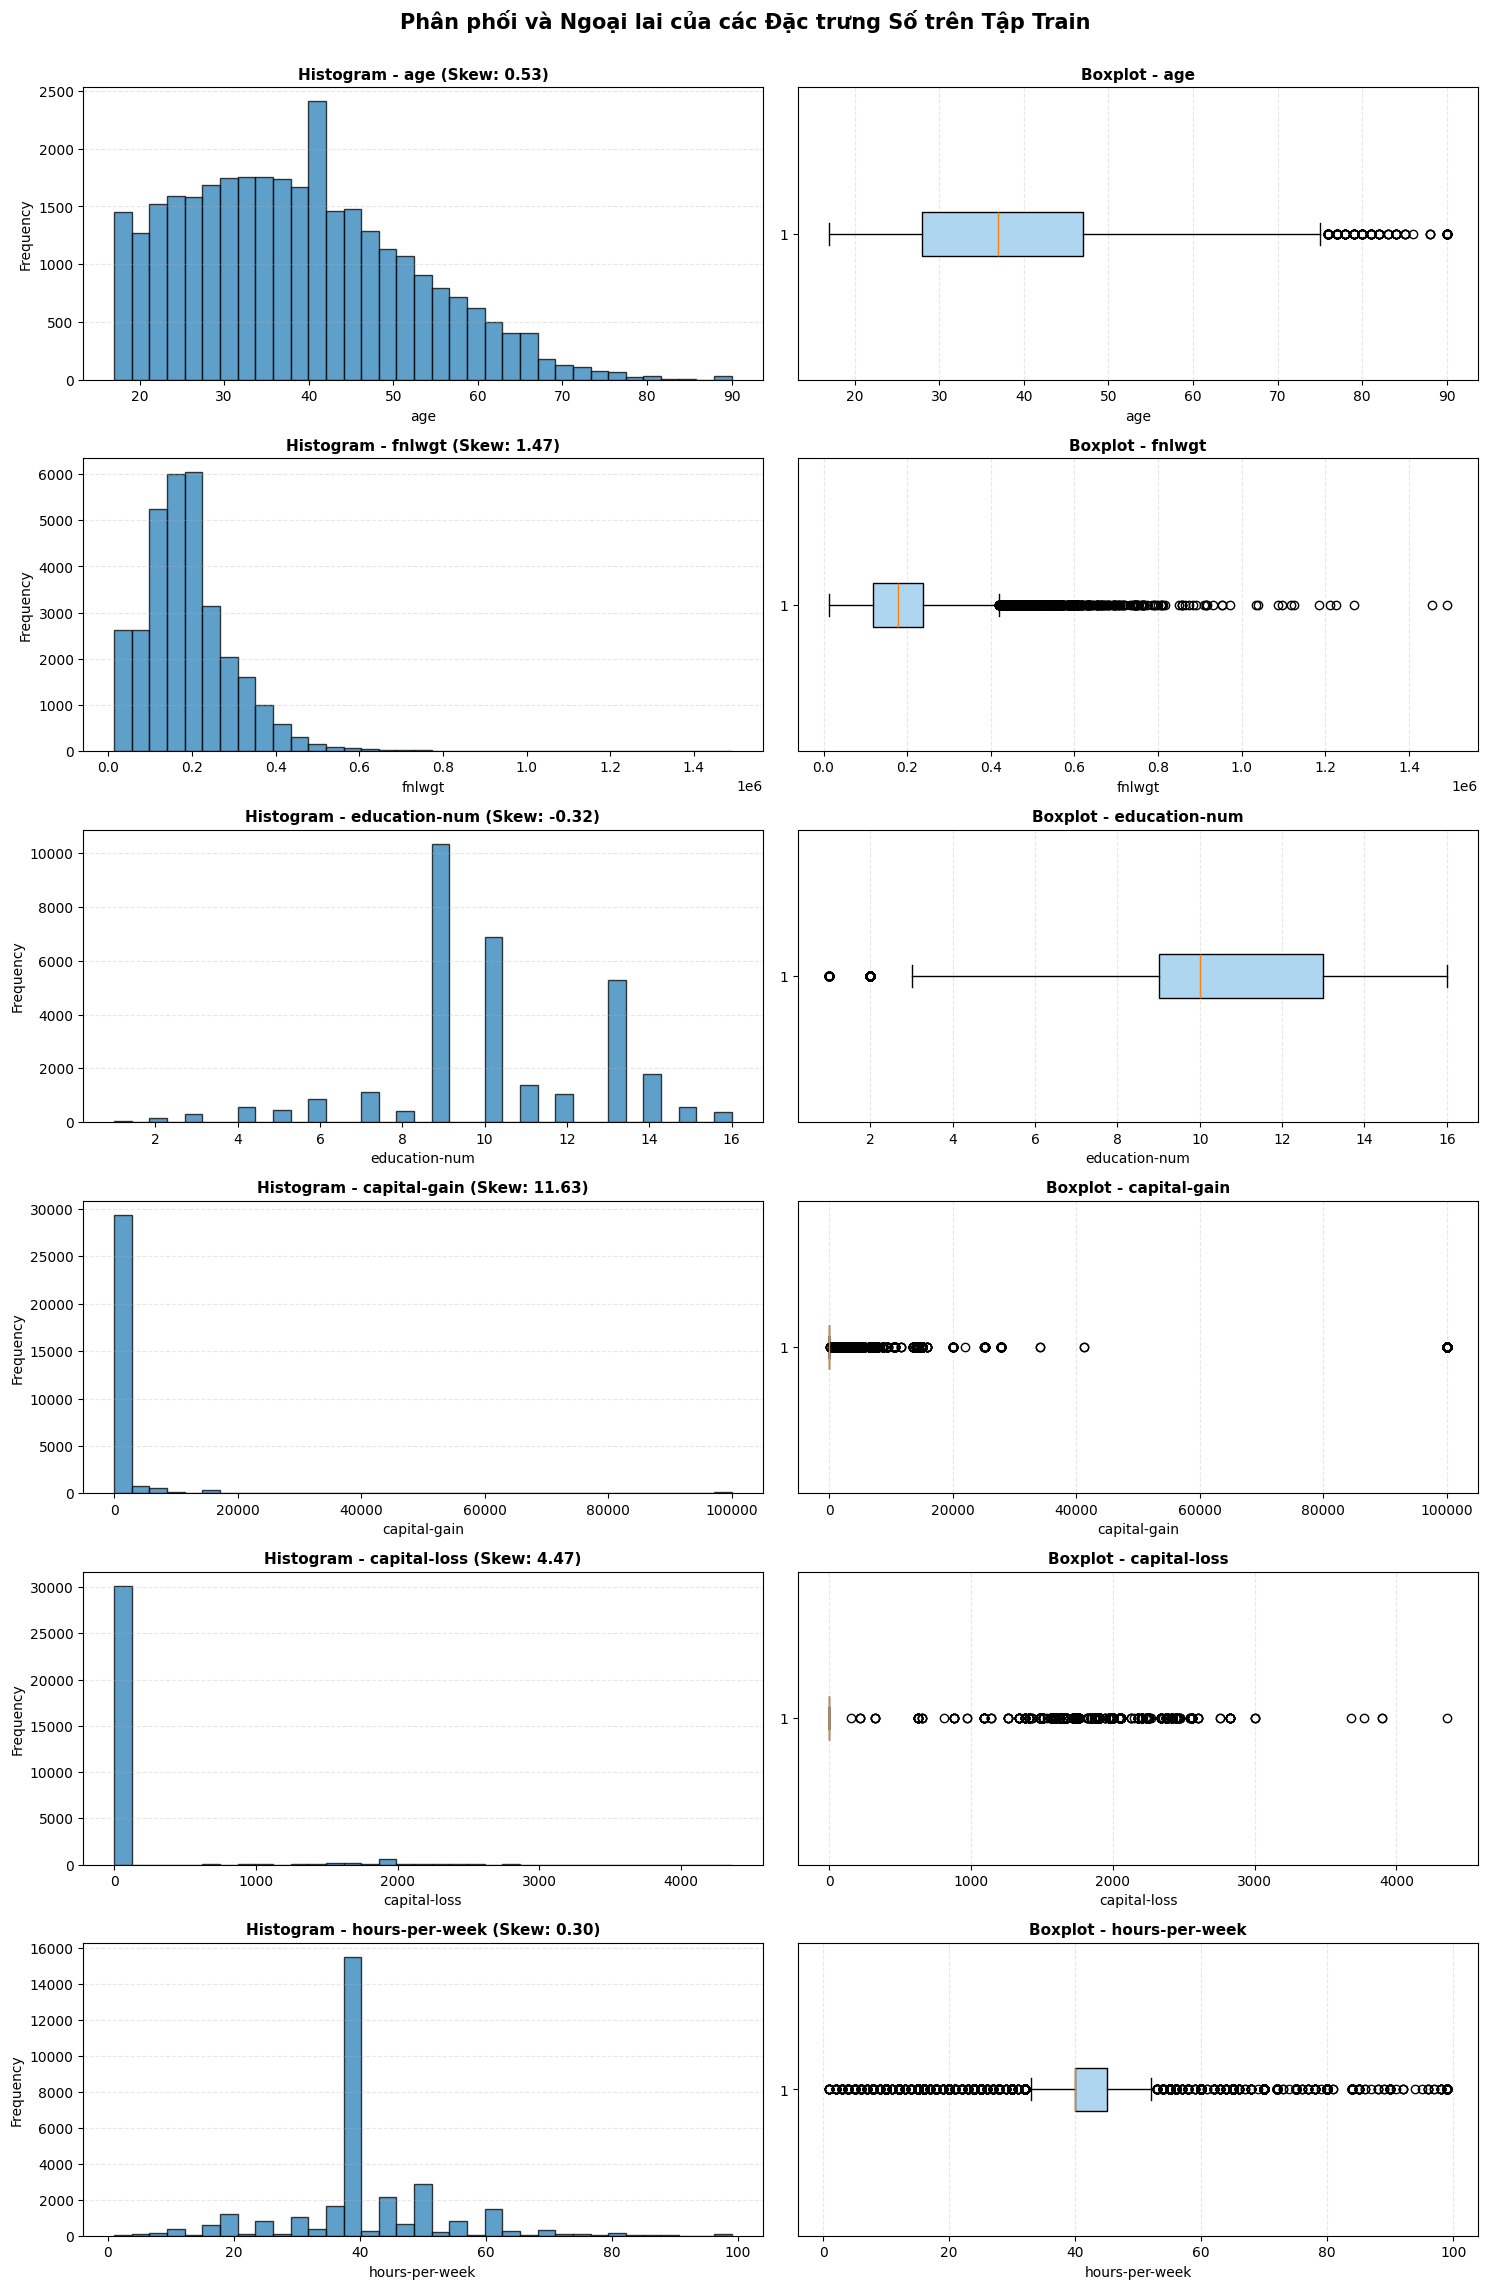

Biểu đồ đã được lưu tại: /content/EDA_result/numerical_feature_distributions_train.png


In [ ]:
import matplotlib.pyplot as plt

# Plot histograms and boxplots for numerical features in X_train
n_num = len(numerical_features)
fig, axes = plt.subplots(n_num, 2, figsize=(15, 3.8 * n_num))

for i, col in enumerate(numerical_features):
    vals = X_train[col].dropna()

    # Histogram
    axes[i, 0].hist(vals, bins=35, color="#2980b9", edgecolor="black", alpha=0.75)
    axes[i, 0].set_title(f"Histogram - {col} (Skew: {vals.skew():.2f})", fontsize=11, fontweight="bold")
    axes[i, 0].set_xlabel(col)
    axes[i, 0].set_ylabel("Frequency")
    axes[i, 0].grid(axis="y", linestyle="--", alpha=0.3)

    # Boxplot
    axes[i, 1].boxplot(vals, vert=False, patch_artist=True, boxprops=dict(facecolor="#aed6f1"))
    axes[i, 1].set_title(f"Boxplot - {col}", fontsize=11, fontweight="bold")
    axes[i, 1].set_xlabel(col)
    axes[i, 1].grid(axis="x", linestyle="--", alpha=0.3)

fig.suptitle("Phân phối và Ngoại lai của các Đặc trưng Số trên Tập Train", fontsize=15, fontweight="bold", y=1.002)
plt.tight_layout()

output_path = EDA_DIR / "numerical_feature_distributions_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


### 4.2.1. Kiểm tra và Xử lý Ngoại lai (Outlier Analysis)

Boxplot giúp phát hiện các giá trị nằm xa phần lớn phân phối, nhưng không phải mọi điểm ngoại lai đều là lỗi dữ liệu. Với bộ Adult, một số biến như `capital-gain` và `capital-loss` có phân phối zero-inflated và đuôi dài; các giá trị lớn có thể mang ý nghĩa thực tế nên không được tự động loại bỏ.

Ở bước này, ta dùng ngưỡng mở rộng `3 × IQR` để nhận diện các giá trị cực đoan trên những đặc trưng số phù hợp. Các quan sát bị đánh dấu ở ít nhất một đặc trưng được thống kê theo tỷ lệ trên Training Set. Chỉ cân nhắc loại bỏ khi tỷ lệ này không vượt quá 10%; nếu vượt ngưỡng hoặc không có căn cứ cho thấy đó là lỗi dữ liệu, giữ nguyên các quan sát. Việc kiểm tra và quyết định chỉ dựa trên Train, không sử dụng Validation/Test.

In [ ]:
# Identify extreme observations using an extended IQR rule (3 x IQR).
# Zero-inflated, strongly skewed capital variables are excluded from automatic filtering.
outlier_check_features = [
    col for col in numerical_features
    if col not in ["capital-gain", "capital-loss"]
]

outlier_flags = pd.DataFrame(False, index=X_train.index, columns=outlier_check_features)
outlier_summary = []

for col in outlier_check_features:
    q1 = X_train[col].quantile(0.25)
    q3 = X_train[col].quantile(0.75)
    iqr = q3 - q1

    if pd.isna(iqr) or iqr == 0:
        lower_bound, upper_bound = float("-inf"), float("inf")
    else:
        lower_bound = q1 - 3 * iqr
        upper_bound = q3 + 3 * iqr

    col_flag = (X_train[col] < lower_bound) | (X_train[col] > upper_bound)
    outlier_flags[col] = col_flag
    outlier_summary.append({
        "Feature": col,
        "Lower bound (3×IQR)": lower_bound,
        "Upper bound (3×IQR)": upper_bound,
        "Extreme observations": int(col_flag.sum()),
        "Percentage (%)": 100 * col_flag.mean()
    })

outlier_summary_df = pd.DataFrame(outlier_summary)
display(outlier_summary_df.round(3))

# A row is a candidate if it is extreme in at least one inspected feature.
outlier_row_mask = outlier_flags.any(axis=1)
n_outlier_rows = int(outlier_row_mask.sum())
outlier_percentage = 100 * n_outlier_rows / len(X_train) if len(X_train) else 0

OUTLIER_REMOVAL_THRESHOLD = 10.0
print(f"Training observations flagged: {n_outlier_rows:,} ({outlier_percentage:.2f}%)")

if 0 < outlier_percentage < OUTLIER_REMOVAL_THRESHOLD:
    print(
        f"Tỷ lệ nhỏ hơn {OUTLIER_REMOVAL_THRESHOLD:.1f}%. "
        "Loại các quan sát được đánh dấu khỏi Training Set theo quy tắc đã xác định."
    )
    keep_mask = ~outlier_row_mask
    X_train = X_train.loc[keep_mask].copy()
    y_train = y_train.loc[keep_mask].copy()
elif n_outlier_rows == 0:
    print("Không phát hiện quan sát cực đoan theo tiêu chí đã chọn; giữ nguyên Training Set.")
else:
    print(
        f"Tỷ lệ đạt hoặc vượt {OUTLIER_REMOVAL_THRESHOLD:.1f}%. "
        "Không tự động loại bỏ để tránh làm mất một phần đáng kể dữ liệu; giữ nguyên Training Set."
    )

print(f"Kích thước Training Set sau bước kiểm tra Outlier: {X_train.shape}")
assert X_train.index.equals(y_train.index), "X_train và y_train không còn đồng bộ."


,Feature,Lower bound (3×IQR),Upper bound (3×IQR),Extreme observations,Percentage (%)
0,age,-29.0,104.0,0,0.000
1,fnlwgt,-244675.0,600410.5,149,0.471
2,education-num,-3.0,25.0,0,0.000
3,hours-per-week,25.0,60.0,3950,12.478


Training observations flagged: 4,088 (12.91%)
Tỷ lệ đạt hoặc vượt 10.0%. Không tự động loại bỏ để tránh làm mất một phần đáng kể dữ liệu; giữ nguyên Training Set.
Kích thước Training Set sau bước kiểm tra Outlier: (31655, 14)


### Cập nhật phân bố lớp sau khi xử lý Outlier

Nếu bước kiểm tra ngoại lai có loại bỏ quan sát, tỷ lệ lớp trong Training Set có thể thay đổi. Vì vậy, ta tính lại `imbalance_ratio` trên dữ liệu Train cuối cùng trước khi sử dụng trong các mô hình.

In [ ]:
train_counts = y_train.value_counts()
neg_count = int(train_counts.get("<=50K", 0))
pos_count = int(train_counts.get(">50K", 0))
imbalance_ratio = neg_count / pos_count if pos_count else 1.0

class_imbalance_df = pd.DataFrame({
    "Class": ["<=50K", ">50K"],
    "Sample Count": [neg_count, pos_count],
    "Percentage (%)": [
        100 * neg_count / len(y_train),
        100 * pos_count / len(y_train)
    ]
})
display(class_imbalance_df.round(2))
print(f"Imbalance ratio (<=50K / >50K): {imbalance_ratio:.3f}")


,Class,Sample Count,Percentage (%)
0,<=50K,23809,75.21
1,>50K,7846,24.79


Imbalance ratio (<=50K / >50K): 3.035


In [ ]:
# Analyze categorical features in X_train
categorical_features = X_train.select_dtypes(
    include=["object", "category"]
).columns.tolist()

cat_summary = []
for col in categorical_features:
    n_unique = X_train[col].nunique()
    top_val = X_train[col].mode()[0]
    top_pct = (X_train[col] == top_val).mean() * 100
    cat_summary.append({
        "Feature": col,
        "Unique Categories": n_unique,
        "Top Category": top_val,
        "Top Category (%)": round(top_pct, 2)
    })

print("Tổng quan các đặc trưng phân loại trên tập Train:")
display(pd.DataFrame(cat_summary))


Tổng quan các đặc trưng phân loại trên tập Train:


,Feature,Unique Categories,Top Category,Top Category (%)
0,workclass,7,Private,73.54
1,education,16,HS-grad,32.70
2,marital-status,7,Married-civ-spouse,46.44
3,occupation,14,Prof-specialty,13.45
4,relationship,6,Husband,41.22
5,race,5,White,86.00
6,sex,2,Male,67.45
7,native-country,41,United-States,91.31


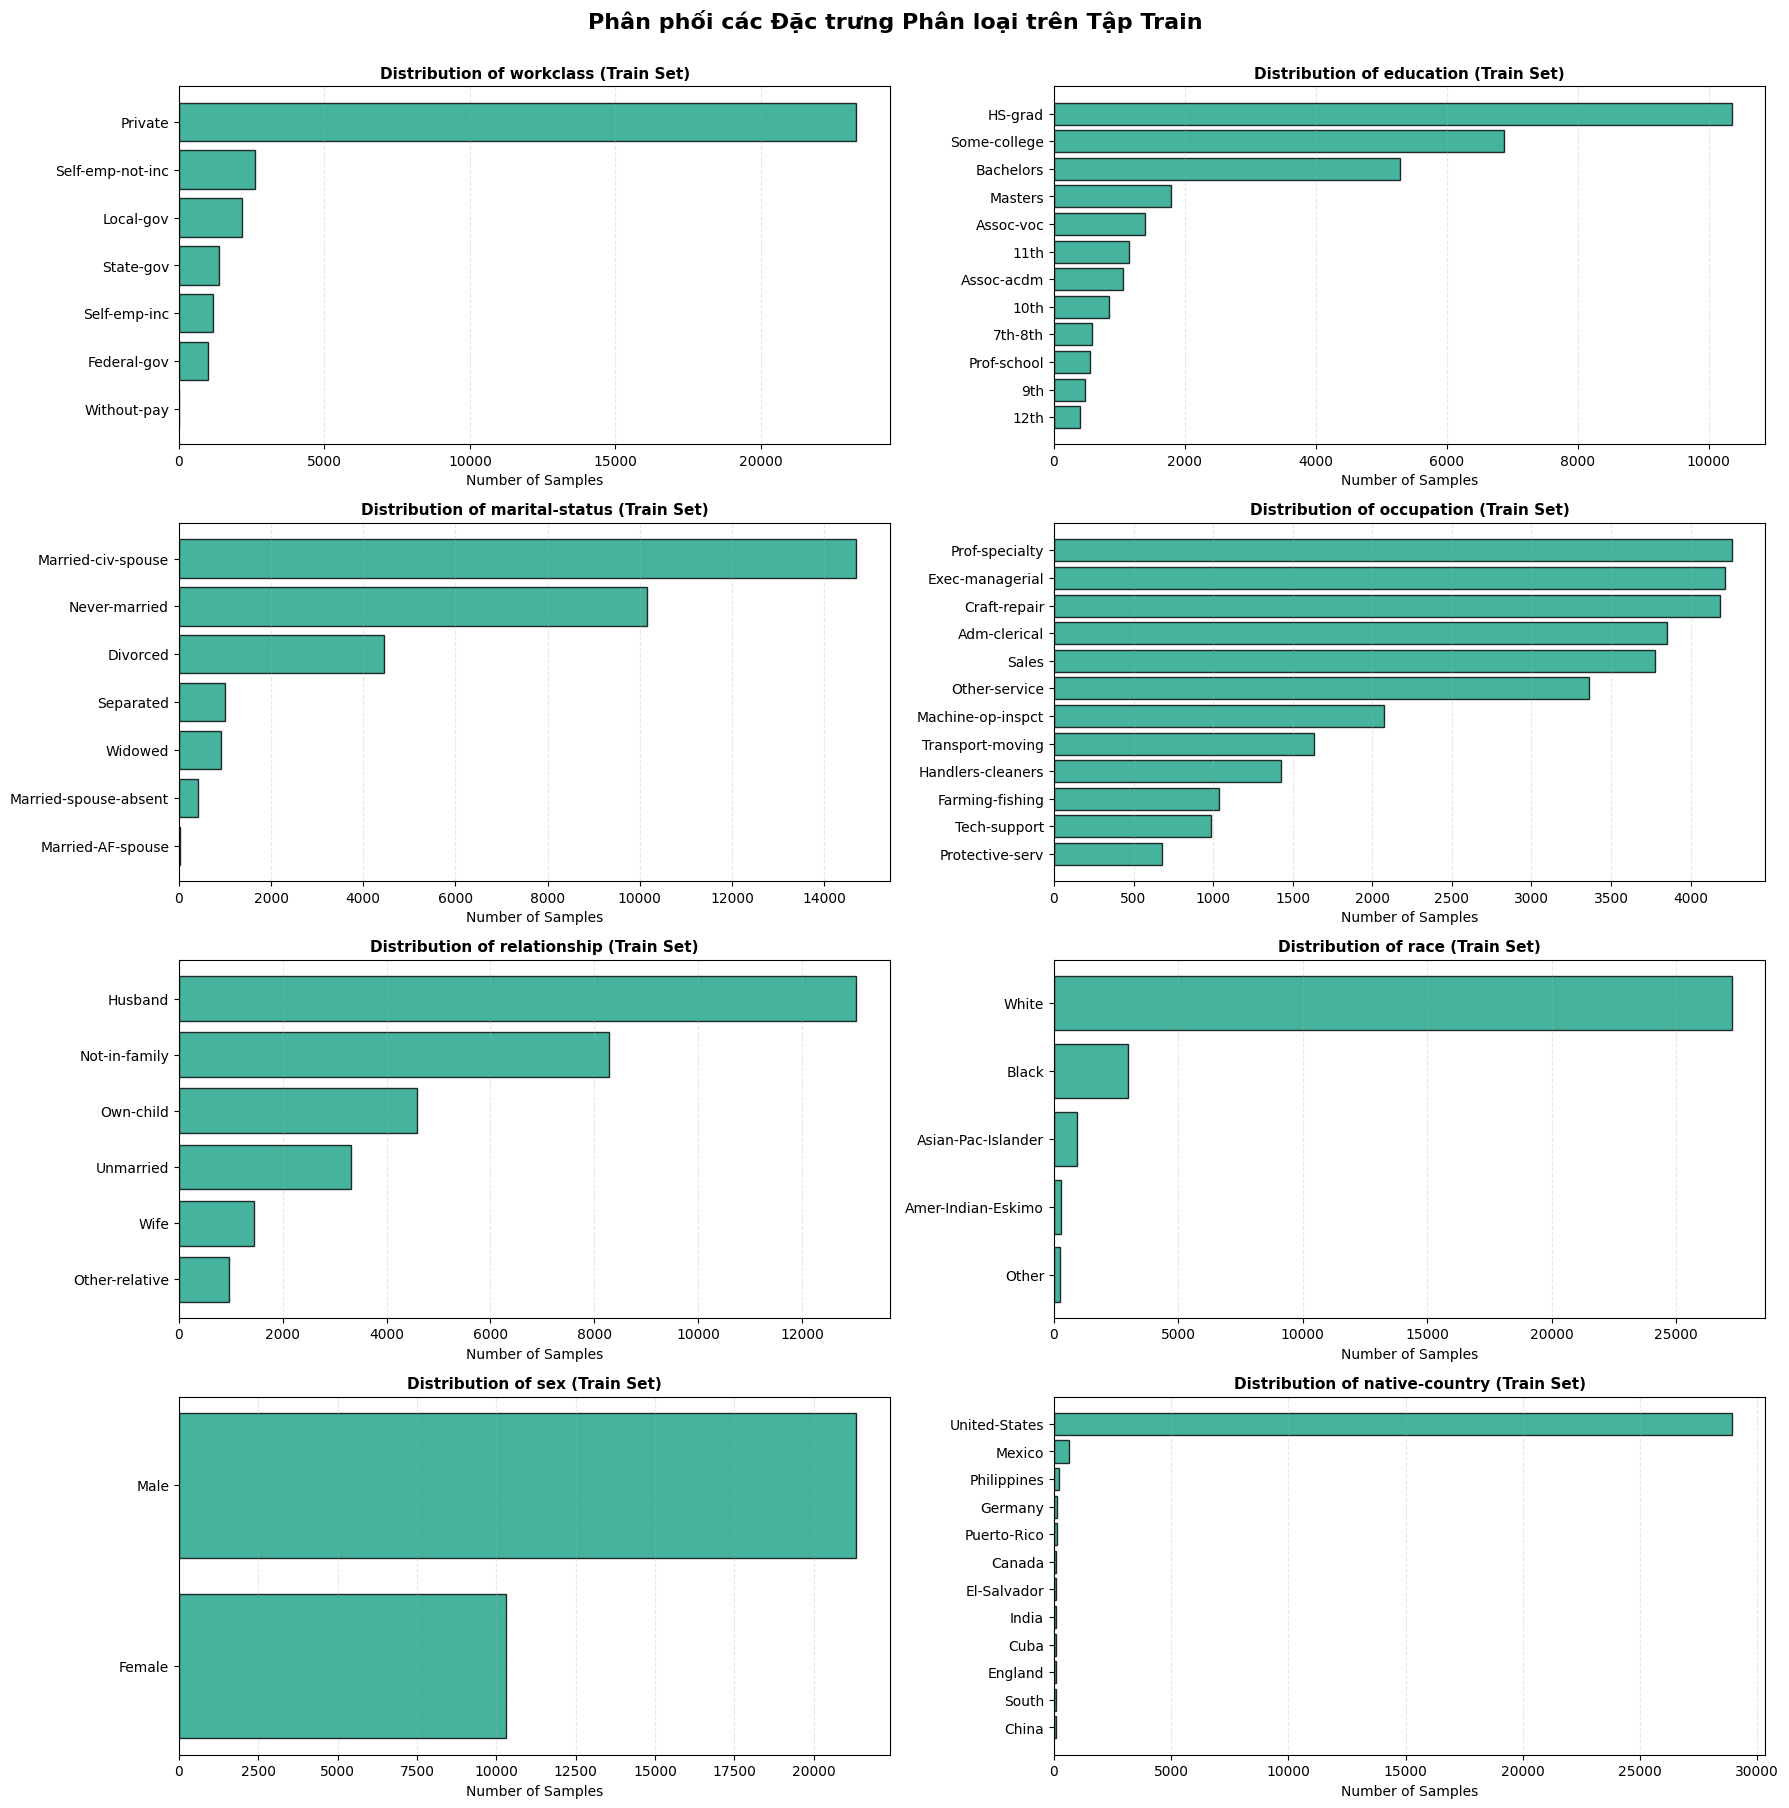

Biểu đồ đã được lưu tại: /content/EDA_result/categorical_feature_distributions_train.png


In [ ]:
import matplotlib.pyplot as plt

# Visualize categorical feature distributions on train set
n_cat = len(categorical_features)
n_cols = 2
n_rows = (n_cat + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, 4.5 * n_rows), squeeze=False)

for i, col in enumerate(categorical_features):
    r, c = divmod(i, n_cols)
    ax = axes[r, c]
    counts = X_train[col].value_counts().head(12)  # Top 12 categories for readability

    ax.barh(counts.index[::-1], counts.values[::-1], color="#16a085", edgecolor="black", alpha=0.8)
    ax.set_title(f"Distribution of {col} (Train Set)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Number of Samples")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

for i in range(n_cat, n_rows * n_cols):
    r, c = divmod(i, n_cols)
    axes[r, c].set_visible(False)

fig.suptitle("Phân phối các Đặc trưng Phân loại trên Tập Train", fontsize=16, fontweight="bold", y=1.002)
plt.tight_layout()

output_path = EDA_DIR / "categorical_feature_distributions_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


## 4.3. Quan hệ giữa các Đặc trưng (Feature-Feature Relationships)

Phân tích này nhằm nhận diện các đặc trưng có thể mang thông tin trùng lặp hoặc tương quan mạnh:
1. Đối chiếu `education` với `education-num` để kiểm tra mức độ tương ứng giữa nhãn học vấn và mã thứ bậc.
2. Khảo sát vai trò của `fnlwgt` trong bộ dữ liệu.
3. Dùng ma trận Pearson correlation để quan sát quan hệ tuyến tính giữa các đặc trưng số.

Tương quan thấp giữa hai biến không tự động chứng minh một biến vô ích đối với dự đoán; quyết định loại biến cần được đối chiếu thêm với quan hệ giữa biến đó và Target.

In [ ]:
# Check mapping between education and education-num
edu_mapping_check = X_train.groupby(["education", "education-num"]).size().reset_index(name="Count")
edu_mapping_check = edu_mapping_check.sort_values(by="education-num")

print("Bảng đối chiếu giữa 'education' và 'education-num' trên tập Train:")
display(edu_mapping_check)

print(f"Số lượng giá trị phân biệt của 'education':     {X_train['education'].nunique()}")
print(f"Số lượng giá trị phân biệt của 'education-num': {X_train['education-num'].nunique()}")
print(f"Số cặp kết hợp duy nhất:                        {len(edu_mapping_check)}")


Bảng đối chiếu giữa 'education' và 'education-num' trên tập Train:


,education,education-num,Count
13,Preschool,1,50
3,1st-4th,2,165
4,5th-6th,3,324
5,7th-8th,4,580
6,9th,5,470
0,10th,6,848
1,11th,7,1140
2,12th,8,399
11,HS-grad,9,10351
15,Some-college,10,6870


Số lượng giá trị phân biệt của 'education':     16
Số lượng giá trị phân biệt của 'education-num': 16
Số cặp kết hợp duy nhất:                        16


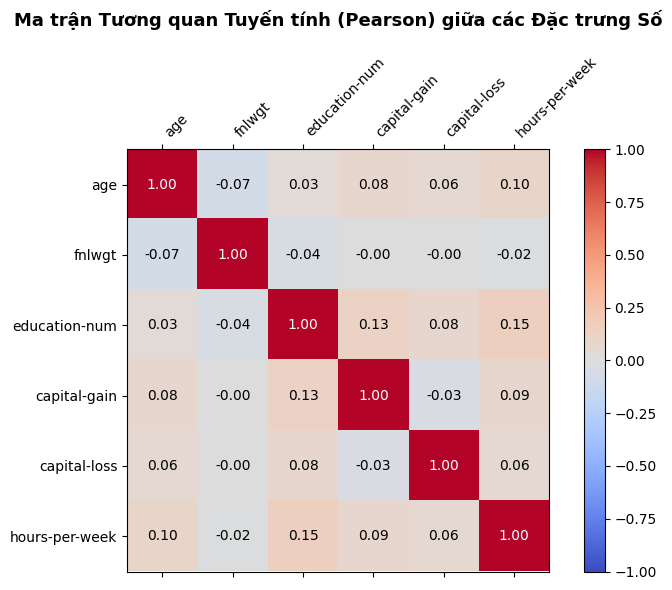

Biểu đồ đã được lưu tại: /content/EDA_result/numerical_correlation_matrix_train.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Correlation matrix among numerical features in X_train
num_corr = X_train[numerical_features].corr()

fig, ax = plt.subplots(figsize=(8, 6))
cax = ax.matshow(num_corr, cmap="coolwarm", vmin=-1, vmax=1)
fig.colorbar(cax)

ax.set_xticks(range(len(numerical_features)))
ax.set_yticks(range(len(numerical_features)))
ax.set_xticklabels(numerical_features, rotation=45, ha="left", fontsize=10)
ax.set_yticklabels(numerical_features, fontsize=10)

# Display correlation values inside cells
for i in range(len(numerical_features)):
    for j in range(len(numerical_features)):
        val = num_corr.iloc[i, j]
        color = "white" if abs(val) > 0.45 else "black"
        ax.text(j, i, f"{val:.2f}", ha="center", va="center", color=color, fontsize=10)

ax.set_title("Ma trận Tương quan Tuyến tính (Pearson) giữa các Đặc trưng Số", fontsize=13, fontweight="bold", pad=20)
plt.tight_layout()

output_path = EDA_DIR / "numerical_correlation_matrix_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


### Nhận xét về Redundancy

Kết quả đối chiếu `education` và `education-num` cho thấy hai biến mô tả cùng khía cạnh học vấn ở hai dạng biểu diễn. Nếu dữ liệu xác nhận ánh xạ một-một, giữ đồng thời cả hai có thể làm tăng số chiều sau One-Hot Encoding mà không bổ sung nhiều thông tin. Vì vậy, `education` là ứng viên có cơ sở để loại bỏ, trong khi giữ `education-num`.

Đối với `fnlwgt`, đây là trọng số mẫu thống kê trong bộ dữ liệu, không phải đặc trưng nhân khẩu học trực tiếp. Tuy nhiên, không nên loại biến chỉ dựa trên tương quan Pearson thấp; cần xem thêm Mutual Information và ý nghĩa của biến. Quyết định cuối cùng được thực hiện ở bước Feature Selection dựa trên kết quả thực tế của Training Set.

## 4.4. Quan hệ giữa Đặc trưng và Biến Mục tiêu (Feature-Target Relationships)

Phân tích mức độ liên hệ giữa từng đặc trưng và `income` trên Training Set:
1. Tính Point-Biserial/Pearson correlation giữa đặc trưng số và Target đã mã hóa nhị phân.
2. So sánh phân phối một số đặc trưng số giữa hai nhóm thu nhập bằng Boxplot.
3. Khảo sát tỷ lệ `>50K` theo các nhóm của đặc trưng phân loại.
4. Ước lượng Mutual Information để phát hiện cả những mối liên hệ không tuyến tính.

Các phép đo này mang tính hỗ trợ lựa chọn đặc trưng, không nên được xem là bằng chứng độc lập về quan hệ nhân quả.

In [ ]:
# Create binary target for analysis on train set
y_train_binary = (y_train == ">50K").astype(int)

# Point-Biserial correlation between numerical features and binary target
train_num_with_target = X_train[numerical_features].copy()
train_num_with_target["target"] = y_train_binary

num_target_corr = train_num_with_target.corr()["target"].drop("target").sort_values(ascending=False)

print("Hệ số tương quan tuyến tính của các biến số với Target (>50K):")
display(pd.DataFrame({
    "Đặc trưng số": num_target_corr.index,
    "Hệ số tương quan (r)": num_target_corr.values.round(4)
}))


Hệ số tương quan tuyến tính của các biến số với Target (>50K):


,Đặc trưng số,Hệ số tương quan (r)
0,education-num,0.3343
1,age,0.2331
2,hours-per-week,0.2239
3,capital-gain,0.2234
4,capital-loss,0.1538
5,fnlwgt,-0.0066


/tmp/ipykernel_499/389476264.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot(
/tmp/ipykernel_499/389476264.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot(
/tmp/ipykernel_499/389476264.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot(
/tmp/ipykernel_499/389476264.py:11: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  bplot = axes[i].boxplot(


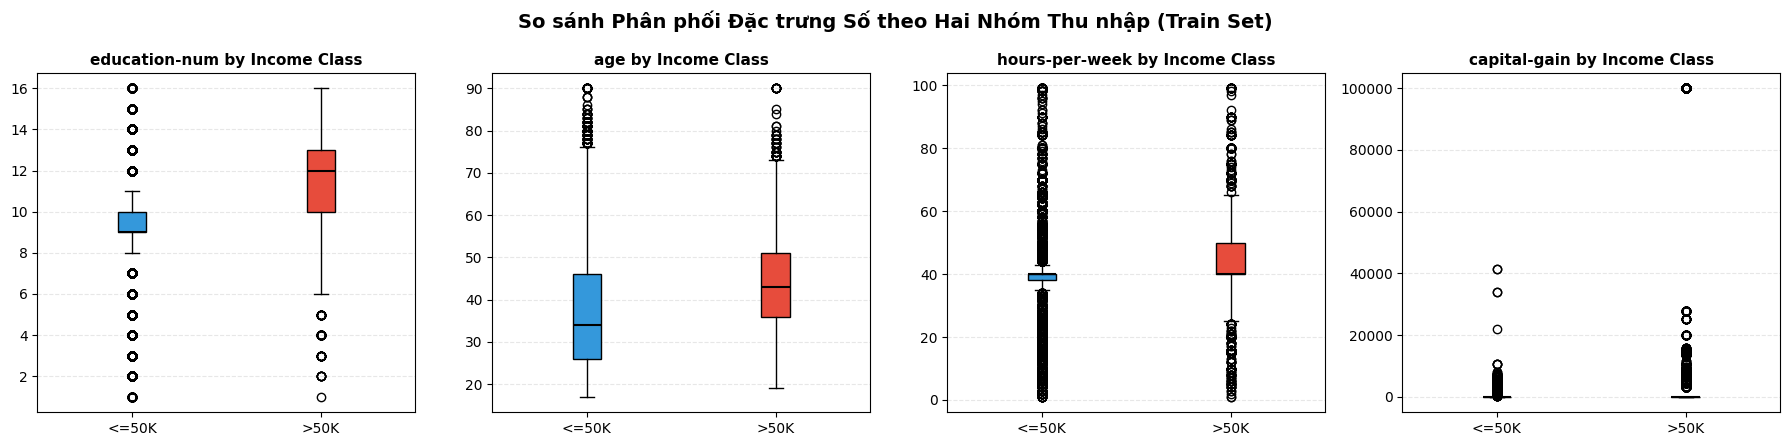

Biểu đồ đã được lưu tại: /content/EDA_result/numerical_vs_target_train.png


In [ ]:
import matplotlib.pyplot as plt

# Compare numerical distributions between income classes using boxplots
cols_to_plot = ["education-num", "age", "hours-per-week", "capital-gain"]
fig, axes = plt.subplots(1, 4, figsize=(18, 4.5))

for i, col in enumerate(cols_to_plot):
    data_low = X_train.loc[y_train == "<=50K", col].dropna()
    data_high = X_train.loc[y_train == ">50K", col].dropna()

    bplot = axes[i].boxplot(
        [data_low, data_high],
        labels=["<=50K", ">50K"],
        patch_artist=True,
        medianprops=dict(color="black", linewidth=1.5)
    )
    bplot["boxes"][0].set_facecolor("#3498db")
    bplot["boxes"][1].set_facecolor("#e74c3c")

    axes[i].set_title(f"{col} by Income Class", fontsize=11, fontweight="bold")
    axes[i].grid(axis="y", linestyle="--", alpha=0.3)

fig.suptitle("So sánh Phân phối Đặc trưng Số theo Hai Nhóm Thu nhập (Train Set)", fontsize=14, fontweight="bold")
plt.tight_layout()

output_path = EDA_DIR / "numerical_vs_target_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


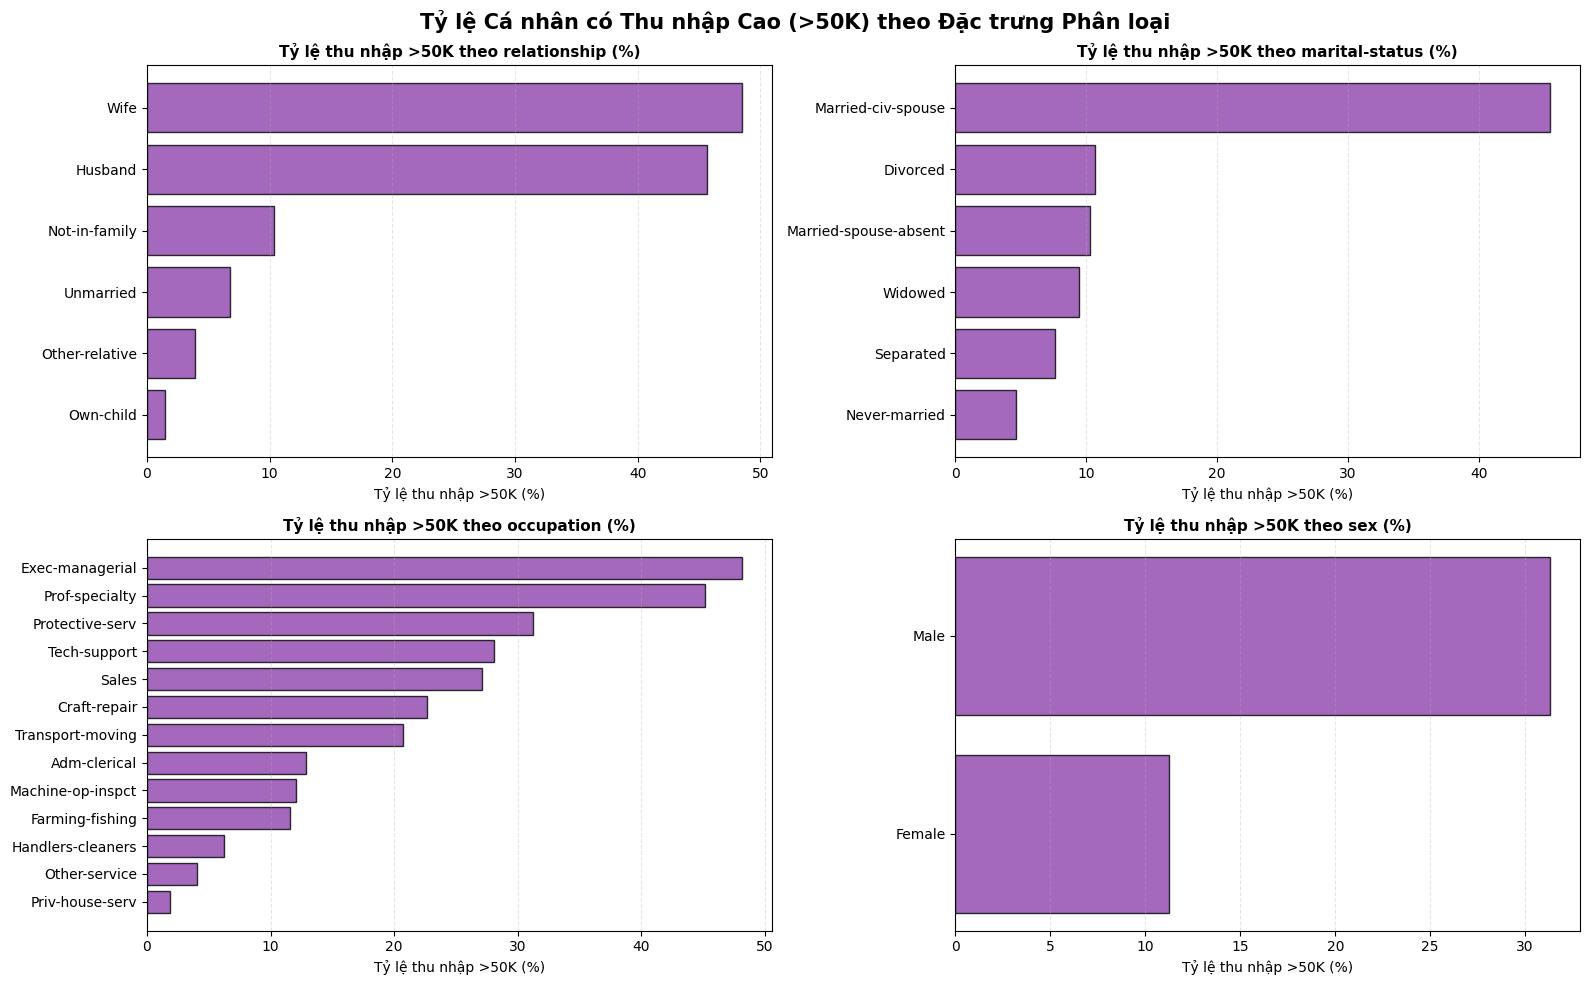

Biểu đồ đã được lưu tại: /content/EDA_result/categorical_vs_target_train.png


In [ ]:
import matplotlib.pyplot as plt

# Analyze high income probability across key categorical features
cat_inspect = ["relationship", "marital-status", "occupation", "sex"]
fig, axes = plt.subplots(2, 2, figsize=(16, 10))
axes = axes.flatten()

for i, col in enumerate(cat_inspect):
    temp_df = pd.DataFrame({col: X_train[col], "target": y_train_binary})
    high_income_rate = temp_df.groupby(col)["target"].agg(["count", "mean"]).sort_values(by="mean", ascending=True)
    high_income_rate = high_income_rate[high_income_rate["count"] >= 50]  # Filter tiny categories

    ax = axes[i]
    ax.barh(high_income_rate.index, high_income_rate["mean"] * 100, color="#8e44ad", edgecolor="black", alpha=0.8)
    ax.set_title(f"Tỷ lệ thu nhập >50K theo {col} (%)", fontsize=11, fontweight="bold")
    ax.set_xlabel("Tỷ lệ thu nhập >50K (%)")
    ax.grid(axis="x", linestyle="--", alpha=0.3)

fig.suptitle("Tỷ lệ Cá nhân có Thu nhập Cao (>50K) theo Đặc trưng Phân loại", fontsize=15, fontweight="bold")
plt.tight_layout()

output_path = EDA_DIR / "categorical_vs_target_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Biểu đồ đã được lưu tại: {output_path.resolve()}")


Xếp hạng Mutual Information giữa các đặc trưng và Target:


,Mutual Information Score
relationship,0.1148
marital-status,0.1096
capital-gain,0.0837
occupation,0.0649
age,0.0644
education,0.0642
education-num,0.0636
hours-per-week,0.0448
capital-loss,0.0368
fnlwgt,0.0268


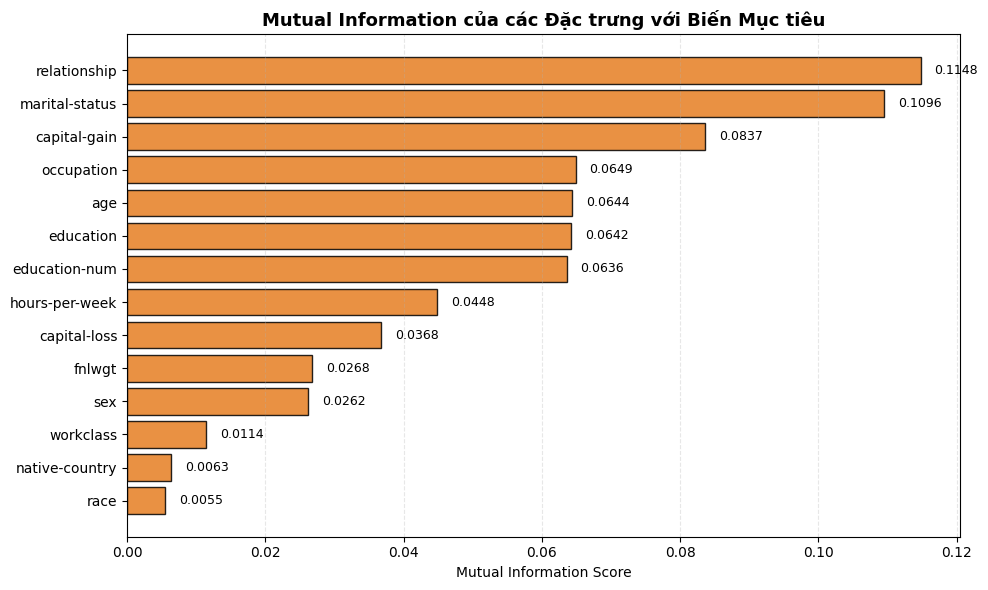

Biểu đồ đã lưu tại: /content/EDA_result/feature_importance_mi_train.png


In [ ]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import OrdinalEncoder
import matplotlib.pyplot as plt
import numpy as np

# Ordinal encoding is used only to estimate MI; categorical columns are explicitly
# marked as discrete so their integer codes are not treated as continuous values.
X_train_encoded_mi = X_train.copy()
cat_cols_mi = X_train.select_dtypes(include=["object", "category"]).columns.tolist()

oe = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
if cat_cols_mi:
    X_train_encoded_mi[cat_cols_mi] = oe.fit_transform(
        X_train_encoded_mi[cat_cols_mi].astype(str)
    )

discrete_mask = np.array([col in cat_cols_mi for col in X_train.columns], dtype=bool)
mi_scores = mutual_info_classif(
    X_train_encoded_mi,
    y_train_binary,
    discrete_features=discrete_mask,
    random_state=42
)

mi_series = pd.Series(mi_scores, index=X_train.columns).sort_values(ascending=True)
print("Xếp hạng Mutual Information giữa các đặc trưng và Target:")
display(mi_series.sort_values(ascending=False).to_frame("Mutual Information Score").round(4))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(mi_series.index, mi_series.values, color="#e67e22", edgecolor="black", alpha=0.85)
ax.set_title("Mutual Information của các Đặc trưng với Biến Mục tiêu", fontsize=13, fontweight="bold")
ax.set_xlabel("Mutual Information Score")
ax.grid(axis="x", linestyle="--", alpha=0.3)
for bar in bars:
    ax.text(bar.get_width() + 0.002, bar.get_y() + bar.get_height() / 2,
            f"{bar.get_width():.4f}", va="center", fontsize=9)
plt.tight_layout()
output_path = EDA_DIR / "feature_importance_mi_train.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Biểu đồ đã lưu tại: {output_path.resolve()}")


### Tổng kết EDA và Cơ sở Feature Selection

Mutual Information, tương quan và các biểu đồ theo nhóm được xem xét đồng thời để đánh giá mức độ hữu ích của đặc trưng. Những biến có điểm Mutual Information thấp cần được kiểm tra thêm, nhưng không loại bỏ chỉ vì thứ hạng thấp nếu chưa có ngưỡng và lập luận phù hợp.

`education` có thể được loại nếu kiểm tra xác nhận thông tin trùng lặp với `education-num`. Các biến còn lại, bao gồm `fnlwgt`, chỉ được loại khi kết quả phân tích trên Training Set cho thấy mức đóng góp rất thấp và quyết định đó có thể giải thích được. Nếu không có đặc trưng nào đáp ứng tiêu chí, giữ nguyên toàn bộ đặc trưng.

## 4.5. Lựa chọn Đặc trưng (Feature Selection)

Feature Selection được thực hiện dựa trên bằng chứng từ EDA, không áp dụng loại bỏ một cách máy móc. Danh sách đặc trưng cần loại được xác định từ kiểm tra redundancy và Mutual Information trên Training Set, sau đó áp dụng nhất quán lên Train, Validation và Test để bảo đảm cùng một schema đầu vào.

In [ ]:
# Feature selection dựa trên redundancy và Mutual Information.
# Ngưỡng có thể điều chỉnh, nhưng không loại biến chỉ vì thứ hạng MI thấp.
MI_LOW_THRESHOLD = 0.005

# education và education-num chỉ được xem là redundancy nếu ánh xạ một-một.
education_is_redundant = False
if {"education", "education-num"}.issubset(X_train.columns):
    education_to_num = X_train.groupby("education")["education-num"].nunique().max()
    num_to_education = X_train.groupby("education-num")["education"].nunique().max()
    education_is_redundant = (education_to_num == 1) and (num_to_education == 1)

redundant_features = ["education"] if education_is_redundant else []

# Các biến có MI rất thấp được đưa vào danh sách ứng viên; quyết định có thể xem xét
# cùng ý nghĩa chuyên môn và kết quả phân tích khác, không dùng tương quan Pearson đơn lẻ.
low_mi_candidates = [
    feature for feature, score in mi_series.items()
    if score < MI_LOW_THRESHOLD and feature in X_train.columns
]

features_to_drop = sorted(set(redundant_features + low_mi_candidates))
features_to_drop = [c for c in features_to_drop if c in X_train.columns]

print(f"Ngưỡng Mutual Information thấp: {MI_LOW_THRESHOLD}")
print("Đặc trưng dư thừa được xác nhận:", redundant_features or "Không có")
print("Ứng viên có Mutual Information thấp:", low_mi_candidates or "Không có")
print("Danh sách đặc trưng sẽ loại:", features_to_drop or "Không có")

# Chỉ loại khi có căn cứ; nếu danh sách rỗng thì giữ nguyên toàn bộ đặc trưng.
X_train_selected = X_train.drop(columns=features_to_drop).copy()
X_val_selected = X_val.drop(columns=features_to_drop).copy()
X_test_selected = X_test.drop(columns=features_to_drop).copy()

print("\nKích thước sau Feature Selection:")
print(f"X_train: {X_train_selected.shape}")
print(f"X_val:   {X_val_selected.shape}")
print(f"X_test:  {X_test_selected.shape}")

print("\nCác đặc trưng được giữ lại:")
for i, col in enumerate(X_train_selected.columns, 1):
    print(f"{i:2d}. {col} ({X_train_selected[col].dtype})")


Ngưỡng Mutual Information thấp: 0.005
Đặc trưng dư thừa được xác nhận: ['education']
Ứng viên có Mutual Information thấp: Không có
Danh sách đặc trưng sẽ loại: ['education']

Kích thước sau Feature Selection:
X_train: (31655, 13)
X_val:   (6783, 13)
X_test:  (6784, 13)

Các đặc trưng được giữ lại:
 1. age (int64)
 2. workclass (object)
 3. fnlwgt (int64)
 4. education-num (int64)
 5. marital-status (object)
 6. occupation (object)
 7. relationship (object)
 8. race (object)
 9. sex (object)
10. capital-gain (int64)
11. capital-loss (int64)
12. hours-per-week (int64)
13. native-country (object)


# 5. Tiền xử lý Dữ liệu (Data Preprocessing)

Sau EDA Round 2 và Feature Selection, 13 đặc trưng còn lại được chuyển đổi sang dạng biểu diễn số phù hợp với đầu vào của các thuật toán Machine Learning.

### Từ quan sát EDA đến quyết định tiền xử lý

Dựa trên kết quả khảo sát từ EDA Round 1 và Round 2, các quyết định tiền xử lý được liên kết chặt chẽ với bằng chứng thực nghiệm như sau:

| Quan sát từ EDA | Bằng chứng thực nghiệm | Quyết định tiền xử lý |
|---|---|---|
| **Lệch phân phối số (Skewness & Outliers)** | `capital-gain` (skew = 11.63) và `capital-loss` (skew = 4.47) lệch phải cực mạnh, zero-inflated; `fnlwgt` (skew = 1.47); Outliers tổng hợp chiếm 12.91% (>10%) nên giữ nguyên. | Áp dụng `StandardScaler` cho 6 đặc trưng số (`age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`) cho các mô hình nhạy cảm khoảng cách (KNN, SVM, MLP). XGBoost và Gaussian Naive Bayes dùng dữ liệu chưa scale. |
| **Đặc trưng phân loại không thứ bậc** | 7 đặc trưng phân loại (`workclass`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`) không có thứ tự tự nhiên; số category từ 2 đến 41. | Sử dụng `OneHotEncoder` với `handle_unknown="ignore"` để tránh lỗi khi gặp category mới ở tập Validation/Test. Sinh ra 82 cột nhị phân, nâng tổng số chiều lên 88. |
| **Dư thừa thông tin (Redundancy)** | `education` và `education-num` có tương ứng 1-1 qua 16 giá trị phân biệt; Mutual Information của cả hai tương đương nhau (~0.064). | Đã loại `education` ở bước Feature Selection, giữ lại `education-num` dưới dạng số để tiết kiệm chiều dữ liệu và bảo toàn thứ bậc học vấn. |
| **Độ phụ thuộc thống kê (Mutual Information)** | Toàn bộ 13 đặc trưng đều có MI > ngưỡng 0.005 (thấp nhất là `race` 0.0055 và `native-country` 0.0063). | Giữ lại toàn bộ 13 đặc trưng đầu vào để mã hóa và huấn luyện. |
| **Mất cân bằng lớp (Class Imbalance)** | Tỷ lệ `imbalance_ratio` ≈ 3.035:1 (75.21% `<=50K` vs 24.79% `>50K`). | Mã hóa nhãn `<=50K` thành 0, `>50K` thành 1. Xử lý mất cân bằng ở giai đoạn huấn luyện (Random Oversampling cho KNN/Naive Bayes, Class Weights cho SVM/XGBoost/MLP). |

> **Nguyên tắc chống rò rỉ dữ liệu (No Data Leakage):**
> Tất cả các phép biến đổi (`OneHotEncoder`, `StandardScaler`) đều chỉ được `fit` trên Training Set (`X_train_selected`). Validation Set và Test Set chỉ áp dụng `transform` dựa trên các tham số đã học từ Training Set.

## 5.1. Phân nhóm Features

Dựa trên kết quả Feature Selection từ 14 đặc trưng ban đầu, `education` đã được loại bỏ do trùng lặp với `education-num`. 13 đặc trưng còn lại được phân tách thành 2 nhóm riêng biệt:
- **Numerical Features (6):** `age`, `fnlwgt`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`.
- **Categorical Features (7):** `workclass`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`.

In [ ]:
# 5.1. Phân nhóm đặc trưng sau Feature Selection
cat_cols = X_train_selected.select_dtypes(
    include=["object", "category", "string"]
).columns.tolist()

num_cols = [c for c in X_train_selected.columns if c not in cat_cols]

print("=" * 65)
print("5.1. PHÂN NHÓM ĐẶC TRƯNG SAU FEATURE SELECTION")
print("=" * 65)
print(f"\n1. Numerical Features ({len(num_cols)} đặc trưng):")
for i, col in enumerate(num_cols, 1):
    skew_val = X_train_selected[col].skew()
    print(f"   {i}. {col:<18} (dtype: {X_train_selected[col].dtype}, Skewness: {skew_val:>6.2f})")

print(f"\n2. Categorical Features ({len(cat_cols)} đặc trưng):")
for i, col in enumerate(cat_cols, 1):
    n_unique = X_train_selected[col].nunique()
    top_cat = X_train_selected[col].mode()[0]
    print(f"   {i}. {col:<18} (Số categories: {n_unique:>2d}, Category phổ biến nhất: {top_cat})")

print(f"\nTổng số đặc trưng đầu vào được đưa vào tiền xử lý: {len(num_cols) + len(cat_cols)}")

## 5.2. One-Hot Encoding

Mã hóa 7 đặc trưng phân loại bằng `OneHotEncoder`:
- Thiết lập `handle_unknown="ignore"` để mô hình không bị lỗi nếu tập Validation hoặc Test xuất hiện category hiếm chưa từng gặp ở Train.
- Thiết lập `sparse_output=False` để trả về ma trận mảng trực tiếp cho Pandas DataFrame.
- **Quan trọng:** Encoder chỉ được `fit` trên `X_train_selected[cat_cols]`, sau đó dùng lại để `transform` đồng nhất cho cả 3 tập dữ liệu.

In [ ]:
import pandas as pd
from sklearn.preprocessing import OneHotEncoder

# Khởi tạo và fit OneHotEncoder CHỈ trên Training Set
encoder = OneHotEncoder(
    handle_unknown="ignore",
    sparse_output=False
)
encoder.fit(X_train_selected[cat_cols])

# Hàm transform nhất quán cho các tập dữ liệu
def encode_features(df_input):
    encoded_arr = encoder.transform(df_input[cat_cols])
    encoded_df = pd.DataFrame(
        encoded_arr,
        columns=encoder.get_feature_names_out(cat_cols),
        index=df_input.index
    )
    num_df = df_input[num_cols].copy()
    return pd.concat([num_df, encoded_df], axis=1)

# Áp dụng encoding cho Train, Validation và Test
X_train_encoded = encode_features(X_train_selected)
X_val_encoded = encode_features(X_val_selected)
X_test_encoded = encode_features(X_test_selected)

n_ohe_cols = X_train_encoded.shape[1] - len(num_cols)

print("=" * 65)
print("5.2. KẾT QUẢ ONE-HOT ENCODING")
print("=" * 65)
print(f"Số đặc trưng số ban đầu:        {len(num_cols)}")
print(f"Số cột sinh ra từ One-Hot:      {n_ohe_cols}")
print(f"Tổng số chiều dữ liệu sau OHE:  {X_train_encoded.shape[1]}")
print("\nKích thước ma trận đặc trưng:")
print(f"  • X_train_encoded : {X_train_encoded.shape[0]:,} mẫu × {X_train_encoded.shape[1]} cột")
print(f"  • X_val_encoded   : {X_val_encoded.shape[0]:,} mẫu × {X_val_encoded.shape[1]} cột")
print(f"  • X_test_encoded  : {X_test_encoded.shape[0]:,} mẫu × {X_test_encoded.shape[1]} cột")

## 5.3. StandardScaler

Chuẩn hóa 6 đặc trưng số bằng `StandardScaler`:
- Đưa các đặc trưng số về phân phối có $\mu = 0$ và $\sigma = 1$:
$$z = \frac{x - \mu_{\text{train}}}{\sigma_{\text{train}}}$$
- Phép biến đổi này tối quan trọng đối với các thuật toán dựa trên khoảng cách hình học hoặc tối ưu hóa gradient như **KNN, SVM, và MLP**.
- Các cột sinh ra từ One-Hot Encoding đã ở thang đo nhị phân $\{0, 1\}$ nên được giữ nguyên vẹn, không chuẩn hóa.
- `StandardScaler` chỉ học trung bình và độ lệch chuẩn từ `X_train_encoded[num_cols]`, sau đó dùng lại các tham số này để chuẩn hóa cho Validation và Test.

In [ ]:
from sklearn.preprocessing import StandardScaler

# Khởi tạo bản sao ma trận cho các mô hình cần scaled (MLP, KNN, SVM)
X_train_mlp = X_train_encoded.copy()
X_val_mlp = X_val_encoded.copy()
X_test_mlp = X_test_encoded.copy()

# Fit scaler CHỈ trên numerical columns của Training Set
scaler = StandardScaler()
X_train_mlp[num_cols] = scaler.fit_transform(X_train_mlp[num_cols])
X_val_mlp[num_cols] = scaler.transform(X_val_mlp[num_cols])
X_test_mlp[num_cols] = scaler.transform(X_test_mlp[num_cols])

print("=" * 65)
print("5.3. CHUẨN HÓA STANDARDSCALER (CHO KNN, SVM, MLP)")
print("=" * 65)
print("Tham số chuẩn hóa học từ Training Set:")
scaler_summary = pd.DataFrame({
    "Numerical Feature": num_cols,
    "Mean (mu)": [scaler.mean_[list(num_cols).index(c)] for c in num_cols],
    "Std (sigma)": [scaler.scale_[list(num_cols).index(c)] for c in num_cols]
})
display(scaler_summary.round(3))

print("\nKiểm tra lại sau chuẩn hóa trên Train (kỳ vọng Mean ≈ 0, Std ≈ 1):")
for col in num_cols:
    m = X_train_mlp[col].mean()
    s = X_train_mlp[col].std()
    print(f"  • {col:<18} -> Mean = {m:>8.4f}, Std = {s:>6.4f}")

## 5.4. Target Encoding

Chuyển đổi nhãn phân loại dạng chuỗi ký tự của biến mục tiêu `income` sang dạng số nguyên:
- Nhãn `<=50K` $\rightarrow$ `0` (Lớp âm - Majority class)
- Nhãn `>50K` $\rightarrow$ `1` (Lớp dương - Minority class)

Ánh xạ này tuân thủ quy chuẩn quốc tế cho bài toán Binary Classification, đồng thời tạo điều kiện thuận lợi cho việc tính toán Loss (như `BCEWithLogitsLoss`), ROC-AUC và Precision/Recall cho lớp thiểu số `>50K`.

In [ ]:
# 5.4. Mã hóa biến mục tiêu: <=50K -> 0, >50K -> 1
target_mapping = {
    "<=50K": 0,
    ">50K": 1
}

y_train = y_train.map(target_mapping).astype("int64")
y_val = y_val.map(target_mapping).astype("int64")
y_test = y_test.map(target_mapping).astype("int64")

# Kiểm tra đảm bảo không có giá trị NaN sau ánh xạ
assert y_train.notna().all(), "Phát hiện nhãn NaN trong y_train!"
assert y_val.notna().all(), "Phát hiện nhãn NaN trong y_val!"
assert y_test.notna().all(), "Phát hiện nhãn NaN trong y_test!"

print("=" * 65)
print("5.4. KẾT QUẢ MÃ HÓA BIẾN MỤC TIÊU (TARGET ENCODING)")
print("=" * 65)
print("Quy tắc ánh xạ: '<=50K' -> 0, '>50K' -> 1")

target_summary = pd.DataFrame({
    "Tập dữ liệu": ["Training", "Validation", "Test"],
    "Tổng số mẫu": [len(y_train), len(y_val), len(y_test)],
    "Lớp 0 (<=50K)": [(y_train == 0).sum(), (y_val == 0).sum(), (y_test == 0).sum()],
    "Lớp 1 (>50K)": [(y_train == 1).sum(), (y_val == 1).sum(), (y_test == 1).sum()],
    "Tỷ lệ Lớp 1 (%)": [
        round((y_train == 1).mean() * 100, 2),
        round((y_val == 1).mean() * 100, 2),
        round((y_test == 1).mean() * 100, 2)
    ]
})
display(target_summary)

In [ ]:
# Kiểm tra tính toàn vẹn và hợp lệ của toàn bộ ma trận dữ liệu
print("=" * 65)
print("KIỂM TRA TÍNH TOÀN VẸN VÀ CHUẨN HÓA DỮ LIỆU")
print("=" * 65)

splits_to_check = [
    ("Train (Unscaled)", X_train_encoded, y_train),
    ("Train (Scaled)",   X_train_mlp,     y_train),
    ("Validation",       X_val_mlp,       y_val),
    ("Test",             X_test_mlp,      y_test),
]

for name, X_s, y_s in splits_to_check:
    non_numeric = X_s.select_dtypes(include=["object", "string", "category"]).columns.tolist()
    has_nan = X_s.isna().any().any()
    assert non_numeric == [], f"Phát hiện đặc trưng phi số trong {name}: {non_numeric}"
    assert not has_nan, f"Phát hiện giá trị thiếu (NaN) trong {name}!"
    assert pd.api.types.is_numeric_dtype(y_s), f"Nhãn mục tiêu trong {name} không phải số!"
    print(f"  ✓ {name:<20}: {X_s.shape[0]:,} dòng × {X_s.shape[1]} cột | All numeric | No NaN | Target valid")

print("\nToàn bộ dữ liệu đã được tiền xử lý đạt chuẩn toán học và sẵn sàng cho mô hình hóa.")

## 5.5. Feature Representation theo từng Mô hình

Tùy theo bản chất lý thuyết của từng thuật toán Machine Learning, hai dạng biểu diễn dữ liệu được chuẩn bị sẵn sàng:

| Dạng dữ liệu đầu vào | Đặc trưng số | Đặc trưng phân loại | Mô hình sử dụng | Cơ sở lý thuyết |
|---|---|---|---|---|
| `X_train_encoded`, `X_val_encoded`, `X_test_encoded` | Giá trị gốc (chưa chuẩn hóa) | One-Hot Encoded (82 cột) | **XGBoost**, **Gaussian Naive Bayes** | Cây quyết định bất biến với phép biến đổi đơn điệu trên thang đo; GaussianNB giả định phân phối Gaussian độc lập. |
| `X_train_mlp`, `X_val_mlp`, `X_test_mlp` | StandardScaler ($\mu=0, \sigma=1$) | One-Hot Encoded (82 cột) | **KNN**, **SVM**, **MLP** | KNN dùng khoảng cách Euclidean; SVM dùng margin cực đại với RBF kernel; MLP tối ưu tham số qua lan truyền ngược gradient. Cả 3 đều đòi hỏi thang đo đồng nhất. |

In [ ]:
# 5.5. Tổng kết Feature Representation cho từng mô hình
print("=" * 65)
print("5.5. TỔNG KẾT DẠNG BIỂU DIỄN DỮ LIỆU THEO TỪNG MÔ HÌNH")
print("=" * 65)

model_data_assignment = {
    "KNN":                  ("X_train_mlp (Scaled)",     X_train_mlp,     "Euclidean distance nhạy cảm với thang đo"),
    "Gaussian Naive Bayes": ("X_train_encoded (OHE)",   X_train_encoded, "Mô hình xác suất Gaussian độc lập"),
    "SVM":                  ("X_train_mlp (Scaled)",     X_train_mlp,     "RBF Kernel & Margin optimization"),
    "XGBoost":              ("X_train_encoded (OHE)",   X_train_encoded, "Tree-based split bất biến với tỷ lệ"),
    "MLP":                  ("X_train_mlp (Scaled)",     X_train_mlp,     "Gradient descent & Backpropagation")
}

summary_rows = []
for model_name, (data_name, data_matrix, note) in model_data_assignment.items():
    summary_rows.append({
        "Mô hình": model_name,
        "Dữ liệu huấn luyện": data_name,
        "Số chiều (Features)": data_matrix.shape[1],
        "Số mẫu (Train)": f"{data_matrix.shape[0]:,}",
        "Lý do kỹ thuật": note
    })

display(pd.DataFrame(summary_rows))
print(f"\nTổng cộng: 6 đặc trưng số + 82 đặc trưng OHE = {X_train_mlp.shape[1]} chiều đầu vào.")

# 6. Xây dựng và Đánh giá Mô hình

Nghiên cứu so sánh đồng thời **năm thuật toán: KNN, Naive Bayes, SVM, XGBoost và MLP**. Cả năm mô hình được xem là các phương án ngang hàng và được đánh giá trên cùng Validation Set và Test Set.

Các chỉ số đánh giá gồm Accuracy, Precision, Recall, F1-score và ROC-AUC. Do dữ liệu có mất cân bằng lớp, kết quả của lớp thiểu số `>50K` (Precision, Recall và F1-score) cũng được theo dõi riêng.

Để xử lý mất cân bằng trong huấn luyện, mỗi mô hình sử dụng một trong hai cách:
- **Class weighting:** XGBoost nhận `scale_pos_weight`, MLP sử dụng `pos_weight` trong hàm loss và SVM sử dụng `class_weight`.
- **Random oversampling:** KNN và Gaussian Naive Bayes không có tham số class-weight trực tiếp trong cấu hình đang sử dụng, vì vậy được huấn luyện trên một Training Set đã oversample lớp thiểu số.

Việc oversampling chỉ được thực hiện trên Training Set. Validation Set và Test Set được giữ nguyên phân phối tự nhiên để việc so sánh phản ánh đúng dữ liệu chưa thấy.

## 6.1. Chuẩn bị dữ liệu huấn luyện và hàm đánh giá chung

`imbalance_ratio` được tính từ Training Set gốc với công thức số mẫu lớp `<=50K` chia cho số mẫu lớp `>50K`. Tập oversampled được tạo bằng cách lấy mẫu có hoàn lại từ lớp thiểu số cho đến khi hai lớp có số lượng bằng nhau.

Các mô hình dùng dữ liệu scaled sẽ sử dụng `X_train_mlp`; Naive Bayes và XGBoost sử dụng dữ liệu One-Hot Encoded chưa chuẩn hóa. Oversampling không được áp dụng lên Validation/Test.

In [ ]:
import copy
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

from sklearn.utils import resample
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, classification_report, ConfusionMatrixDisplay
)
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVC

RESULT_DIR = Path("Model_result")
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# Class distribution and imbalance ratio on the original training set
class_counts = y_train.value_counts()
negative_count = int(class_counts.get(0, 0))
positive_count = int(class_counts.get(1, 0))
imbalance_ratio = negative_count / positive_count if positive_count else 1.0

print("Original training distribution:")
print(class_counts.sort_index().rename(index={0: "<=50K", 1: ">50K"}))
print(f"Imbalance ratio (majority / minority): {imbalance_ratio:.3f}")

# Random oversampling: resample only the minority class in the training set.
train_for_resampling = X_train_encoded.copy()
train_for_resampling["_target_"] = y_train.to_numpy()

majority_df = train_for_resampling[train_for_resampling["_target_"] == 0]
minority_df = train_for_resampling[train_for_resampling["_target_"] == 1]

minority_upsampled = resample(
    minority_df,
    replace=True,
    n_samples=len(majority_df),
    random_state=42
)

train_upsampled = pd.concat(
    [majority_df, minority_upsampled],
    axis=0
).sample(frac=1, random_state=42)

y_train_upsampled = train_upsampled.pop("_target_").astype("int64")
X_train_upsampled_encoded = train_upsampled

# Apply the already-fitted scaler to the oversampled feature rows.
X_train_upsampled_scaled = X_train_upsampled_encoded.copy()
X_train_upsampled_scaled[num_cols] = scaler.transform(
    X_train_upsampled_scaled[num_cols]
)

print("\nUpsampled training distribution:")
print(y_train_upsampled.value_counts().sort_index().rename(index={0: "<=50K", 1: ">50K"}))
print(f"Original train size:  {len(y_train):,}")
print(f"Upsampled train size: {len(y_train_upsampled):,}")
print("Validation and Test sets remain unchanged.")

def calculate_metrics(y_true, y_pred, y_proba, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Precision (>50K)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (>50K)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score (>50K)": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

Original training distribution:
income
<=50K    23809
>50K      7846
Name: count, dtype: int64
Imbalance ratio (majority / minority): 3.035

Upsampled training distribution:
_target_
<=50K    23809
>50K     23809
Name: count, dtype: int64
Original train size:  31,655
Upsampled train size: 47,618
Validation and Test sets remain unchanged.


## 6.2. XGBoost

XGBoost là mô hình Ensemble dựa trên Decision Trees. Mô hình sử dụng `scale_pos_weight`, được thiết lập bằng `imbalance_ratio` tính từ Training Set gốc, nhằm tăng trọng số cho lớp thiểu số trong quá trình tối ưu.

In [ ]:
xgb_model = XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    n_estimators=300,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=imbalance_ratio,
    random_state=42,
    n_jobs=-1,
    tree_method="hist"
)

xgb_model.fit(X_train_encoded, y_train)

y_val_pred_xgb = xgb_model.predict(X_val_encoded)
y_val_proba_xgb = xgb_model.predict_proba(X_val_encoded)[:, 1]
print("XGBoost training completed with scale_pos_weight =", round(imbalance_ratio, 3))

XGBoost training completed with scale_pos_weight = 3.035


## 6.3. Multi-Layer Perceptron (MLP)

MLP là mạng nơ-ron truyền thẳng gồm nhiều tầng Fully Connected. Đầu vào được chuẩn hóa bằng `StandardScaler`; `Dropout` và `Early Stopping` được sử dụng nhằm hạn chế Overfitting. Mất cân bằng lớp được xử lý bằng `pos_weight` trong `BCEWithLogitsLoss`.

Using device: cuda
Epoch 01/50 | Train: 0.6462 | Val: 0.5700
Epoch 02/50 | Train: 0.5680 | Val: 0.5670
Epoch 03/50 | Train: 0.5613 | Val: 0.5585
Epoch 04/50 | Train: 0.5554 | Val: 0.5555
Epoch 05/50 | Train: 0.5518 | Val: 0.5553
Epoch 06/50 | Train: 0.5479 | Val: 0.5574
Epoch 07/50 | Train: 0.5466 | Val: 0.5556
Epoch 08/50 | Train: 0.5407 | Val: 0.5557
Epoch 09/50 | Train: 0.5380 | Val: 0.5571
Epoch 10/50 | Train: 0.5348 | Val: 0.5623
Early stopping at epoch 10


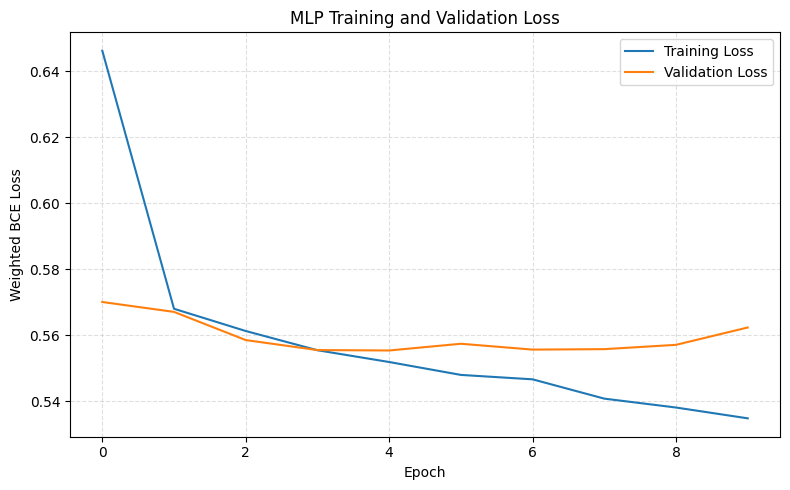

MLP training completed with BCEWithLogitsLoss(pos_weight=3.035).


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)

def to_tensor(X_df, y_s):
    X_t = torch.tensor(X_df.to_numpy(dtype=np.float32), dtype=torch.float32)
    y_t = torch.tensor(np.asarray(y_s, dtype=np.float32).reshape(-1, 1), dtype=torch.float32)
    return TensorDataset(X_t, y_t)

BATCH_SIZE = 256
train_dataset = to_tensor(X_train_mlp, y_train)
val_dataset = to_tensor(X_val_mlp, y_val)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

class MLPClassifier(nn.Module):
    def __init__(self, input_dim):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 256), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.2),
            nn.Linear(128, 1)
        )

    def forward(self, x):
        return self.network(x)

mlp_model = MLPClassifier(input_dim=X_train_mlp.shape[1]).to(device)
pos_weight_tensor = torch.tensor([imbalance_ratio], dtype=torch.float32, device=device)
criterion = nn.BCEWithLogitsLoss(pos_weight=pos_weight_tensor)
optimizer = torch.optim.Adam(mlp_model.parameters(), lr=1e-3, weight_decay=1e-4)

NUM_EPOCHS = 50
PATIENCE = 5
best_val_loss = float("inf")
best_state = None
epochs_without_improvement = 0
history = {"train_loss": [], "val_loss": []}

for epoch in range(NUM_EPOCHS):
    mlp_model.train()
    train_loss_sum = 0.0
    for X_batch, y_batch in train_loader:
        X_batch, y_batch = X_batch.to(device), y_batch.to(device)
        optimizer.zero_grad()
        loss = criterion(mlp_model(X_batch), y_batch)
        loss.backward()
        optimizer.step()
        train_loss_sum += loss.item() * X_batch.size(0)

    train_loss = train_loss_sum / len(train_dataset)

    mlp_model.eval()
    val_loss_sum = 0.0
    with torch.no_grad():
        for X_batch, y_batch in val_loader:
            X_batch, y_batch = X_batch.to(device), y_batch.to(device)
            loss = criterion(mlp_model(X_batch), y_batch)
            val_loss_sum += loss.item() * X_batch.size(0)

    val_loss = val_loss_sum / len(val_dataset)
    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)
    print(f"Epoch {epoch + 1:02d}/{NUM_EPOCHS} | Train: {train_loss:.4f} | Val: {val_loss:.4f}")

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        best_state = copy.deepcopy(mlp_model.state_dict())
        epochs_without_improvement = 0
    else:
        epochs_without_improvement += 1

    if epochs_without_improvement >= PATIENCE:
        print(f"Early stopping at epoch {epoch + 1}")
        break

if best_state is not None:
    mlp_model.load_state_dict(best_state)

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(history["train_loss"], label="Training Loss")
ax.plot(history["val_loss"], label="Validation Loss")
ax.set(title="MLP Training and Validation Loss", xlabel="Epoch", ylabel="Weighted BCE Loss")
ax.legend()
ax.grid(linestyle="--", alpha=0.4)
fig.tight_layout()
fig.savefig(RESULT_DIR / "mlp_training_curves.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

mlp_model.eval()
val_logits = []
with torch.no_grad():
    for X_batch, _ in val_loader:
        val_logits.extend(mlp_model(X_batch.to(device)).cpu().numpy().ravel())
y_val_proba_mlp = torch.sigmoid(torch.tensor(val_logits)).numpy()
y_val_pred_mlp = (y_val_proba_mlp >= 0.5).astype(int)

print(f"MLP training completed with BCEWithLogitsLoss(pos_weight={imbalance_ratio:.3f}).")

## 6.4. K-Nearest Neighbors (KNN)

KNN phân loại dựa trên nhãn của các láng giềng gần nhất và nhạy với thang đo của đặc trưng. Vì KNN không có tham số `class_weight` trong cấu hình này, mô hình được huấn luyện trên Training Set đã random-oversampling và sử dụng dữ liệu đã chuẩn hóa.

In [ ]:
knn_model = KNeighborsClassifier(
    n_neighbors=7,
    weights="distance",
    metric="minkowski",
    p=2,
    n_jobs=-1
)
knn_model.fit(X_train_upsampled_scaled, y_train_upsampled)

y_val_pred_knn = knn_model.predict(X_val_mlp)
y_val_proba_knn = knn_model.predict_proba(X_val_mlp)[:, 1]
print("KNN training completed on the upsampled training set.")

KNN training completed on the upsampled training set.


## 6.5. Gaussian Naive Bayes

Gaussian Naive Bayes là mô hình xác suất dựa trên giả định độc lập có điều kiện giữa các đặc trưng và phân phối Gaussian. Do mô hình không cung cấp cơ chế class-weight trực tiếp trong cách huấn luyện này, nó được train trên Training Set đã random-oversampling. Đầu vào là dữ liệu One-Hot Encoded.

In [ ]:
nb_model = GaussianNB()
nb_model.fit(X_train_upsampled_encoded, y_train_upsampled)

y_val_pred_nb = nb_model.predict(X_val_encoded)
y_val_proba_nb = nb_model.predict_proba(X_val_encoded)[:, 1]
print("Gaussian Naive Bayes training completed on the upsampled training set.")

Gaussian Naive Bayes training completed on the upsampled training set.


## 6.6. Support Vector Machine (SVM)

SVM sử dụng RBF kernel để mô hình hóa ranh giới phân loại phi tuyến. Dữ liệu được chuẩn hóa bằng `StandardScaler`; `class_weight={0: 1.0, 1: imbalance_ratio}` truyền trực tiếp tỷ lệ mất cân bằng đã tính từ Training Set gốc.

In [ ]:
svm_model = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale",
    class_weight={0: 1.0, 1: imbalance_ratio},
    probability=True,
    random_state=42
)
svm_model.fit(X_train_mlp, y_train)

y_val_pred_svm = svm_model.predict(X_val_mlp)
y_val_proba_svm = svm_model.predict_proba(X_val_mlp)[:, 1]
print(f"SVM training completed with class_weight={{0: 1.0, 1: {imbalance_ratio:.3f}}}.")

SVM training completed with class_weight={0: 1.0, 1: 3.035}.


## 6.7. So sánh chung trên Validation Set

Tất cả năm mô hình được đánh giá trên cùng Validation Set với phân phối lớp gốc. Bảng kết quả và Confusion Matrix được trình bày chung để việc so sánh không bị chia thành các nhóm thuật toán.

,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Precision (>50K),Recall (>50K),F1-score (>50K)
0,KNN,0.7836,0.5447,0.7722,0.6388,0.8541,0.5447,0.7722,0.6388
1,Naive Bayes,0.7843,0.6369,0.3016,0.4094,0.8337,0.6369,0.3016,0.4094
2,SVM,0.8079,0.5752,0.8596,0.6892,0.9032,0.5752,0.8596,0.6892
3,XGBoost,0.8322,0.6155,0.8608,0.7178,0.9270,0.6155,0.8608,0.7178
4,MLP,0.8072,0.5738,0.8626,0.6892,0.9123,0.5738,0.8626,0.6892


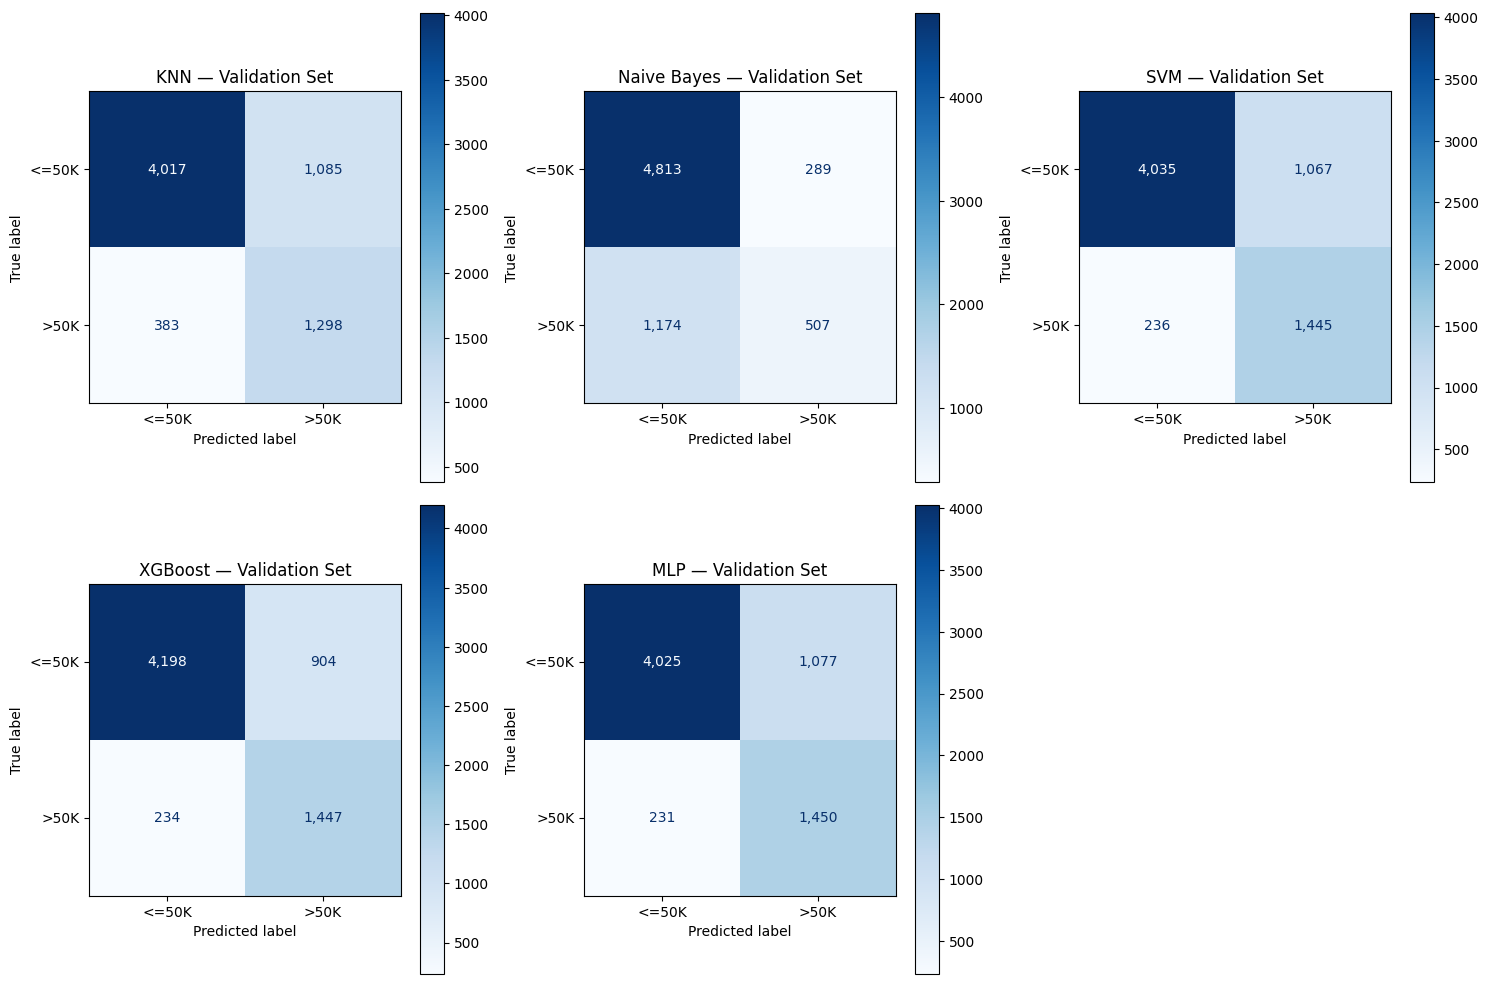

KNN — Validation Set
              precision    recall  f1-score   support

       <=50K       0.91      0.79      0.85      5102
        >50K       0.54      0.77      0.64      1681

    accuracy                           0.78      6783
   macro avg       0.73      0.78      0.74      6783
weighted avg       0.82      0.78      0.79      6783

Naive Bayes — Validation Set
              precision    recall  f1-score   support

       <=50K       0.80      0.94      0.87      5102
        >50K       0.64      0.30      0.41      1681

    accuracy                           0.78      6783
   macro avg       0.72      0.62      0.64      6783
weighted avg       0.76      0.78      0.75      6783

SVM — Validation Set
              precision    recall  f1-score   support

       <=50K       0.94      0.79      0.86      5102
        >50K       0.58      0.86      0.69      1681

    accuracy                           0.81      6783
   macro avg       0.76      0.83      0.78      6783
wei

In [ ]:
validation_outputs = {
    "KNN": (y_val_pred_knn, y_val_proba_knn),
    "Naive Bayes": (y_val_pred_nb, y_val_proba_nb),
    "SVM": (y_val_pred_svm, y_val_proba_svm),
    "XGBoost": (y_val_pred_xgb, y_val_proba_xgb),
    "MLP": (y_val_pred_mlp, y_val_proba_mlp)
}

all_validation_results = pd.DataFrame([
    calculate_metrics(y_val, pred, proba, model_name)
    for model_name, (pred, proba) in validation_outputs.items()
])

display(all_validation_results.round(4))
all_validation_results.to_csv(
    RESULT_DIR / "all_models_validation_metrics.csv",
    index=False
)

fig, axes = plt.subplots(2, 3, figsize=(15, 10))
axes = axes.ravel()
for ax, (model_name, (pred, _)) in zip(axes, validation_outputs.items()):
    ConfusionMatrixDisplay.from_predictions(
        y_val, pred,
        labels=[0, 1],
        display_labels=["<=50K", ">50K"],
        cmap="Blues",
        values_format=",",
        ax=ax
    )
    ax.set_title(f"{model_name} — Validation Set")
for ax in axes[len(validation_outputs):]:
    ax.set_visible(False)
fig.tight_layout()
fig.savefig(RESULT_DIR / "all_models_validation_confusion_matrices.png", dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

for model_name, (pred, _) in validation_outputs.items():
    print("=" * 68)
    print(f"{model_name} — Validation Set")
    print(classification_report(
        y_val, pred, labels=[0, 1],
        target_names=["<=50K", ">50K"],
        zero_division=0
    ))

## 6.8. So sánh các Mô hình trên Test Set

Sau khi hoàn tất quá trình phát triển mô hình và xem xét kết quả Validation, các mô hình được đánh giá trên Test Set độc lập. Test Set không tham gia vào EDA, Feature Selection, fit Encoder/Scaler hoặc lựa chọn siêu tham số. Các chỉ số được báo cáo gồm Accuracy, Precision, Recall, F1-score và ROC-AUC; đồng thời xem xét riêng lớp thu nhập cao `>50K`.

In [ ]:
# Predictions on the untouched Test Set
test_model_specs = {
    "XGBoost": (xgb_model, X_test_encoded),
    "MLP": (mlp_model, X_test_mlp),
    "KNN": (knn_model, X_test_mlp),
    "Naive Bayes": (nb_model, X_test_encoded),
    "SVM": (svm_model, X_test_mlp)
}

test_predictions = {}
for model_name, (model, X_input) in test_model_specs.items():
    if model_name == "MLP":
        model.eval()
        X_tensor = torch.tensor(
            X_input.to_numpy(dtype=np.float32),
            dtype=torch.float32,
            device=device
        )
        with torch.no_grad():
            logits = model(X_tensor).squeeze(1)
            y_proba = torch.sigmoid(logits).cpu().numpy()
        y_pred = (y_proba >= 0.5).astype(int)
    else:
        y_pred = model.predict(X_input)
        y_proba = model.predict_proba(X_input)[:, 1]

    test_predictions[model_name] = {
        "y_pred": np.asarray(y_pred),
        "y_proba": np.asarray(y_proba)
    }

def calculate_metrics(y_true, y_pred, y_proba, model_name):
    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision": precision_score(y_true, y_pred, zero_division=0),
        "Recall": recall_score(y_true, y_pred, zero_division=0),
        "F1-score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_proba),
        "Precision (>50K)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (>50K)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "F1-score (>50K)": f1_score(y_true, y_pred, pos_label=1, zero_division=0)
    }

test_comparison_results = pd.DataFrame([
    calculate_metrics(
        y_test,
        test_predictions[name]["y_pred"],
        test_predictions[name]["y_proba"],
        name
    )
    for name in test_model_specs
])

print("=" * 78)
print("SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TEST SET")
print("=" * 78)
display(test_comparison_results.round(4))

test_comparison_results.to_csv(RESULT_DIR / "all_models_test_comparison.csv", index=False)
print(f"Kết quả đã lưu tại: {(RESULT_DIR / 'all_models_test_comparison.csv').resolve()}")


SO SÁNH HIỆU NĂNG CÁC MÔ HÌNH TRÊN TEST SET


,Model,Accuracy,Precision,Recall,F1-score,ROC-AUC,Precision (>50K),Recall (>50K),F1-score (>50K)
0,XGBoost,0.8302,0.6111,0.8656,0.7164,0.9265,0.6111,0.8656,0.7164
1,MLP,0.8056,0.5708,0.8679,0.6887,0.9093,0.5708,0.8679,0.6887
2,KNN,0.7833,0.5443,0.7710,0.6381,0.8579,0.5443,0.7710,0.6381
3,Naive Bayes,0.7824,0.6296,0.2963,0.4029,0.8280,0.6296,0.2963,0.4029
4,SVM,0.8025,0.5661,0.8691,0.6856,0.8997,0.5661,0.8691,0.6856


Kết quả đã lưu tại: /content/Model_result/all_models_test_comparison.csv


In [ ]:
from sklearn.metrics import classification_report

for model_name, prediction in test_predictions.items():
    print("=" * 68)
    print(f"{model_name} — Test Set Classification Report")
    print("=" * 68)
    print(classification_report(
        y_test, prediction["y_pred"],
        labels=[0, 1], target_names=["<=50K", ">50K"], zero_division=0
    ))


XGBoost — Test Set Classification Report
              precision    recall  f1-score   support

       <=50K       0.95      0.82      0.88      5103
        >50K       0.61      0.87      0.72      1681

    accuracy                           0.83      6784
   macro avg       0.78      0.84      0.80      6784
weighted avg       0.87      0.83      0.84      6784

MLP — Test Set Classification Report
              precision    recall  f1-score   support

       <=50K       0.95      0.79      0.86      5103
        >50K       0.57      0.87      0.69      1681

    accuracy                           0.81      6784
   macro avg       0.76      0.83      0.77      6784
weighted avg       0.85      0.81      0.82      6784

KNN — Test Set Classification Report
              precision    recall  f1-score   support

       <=50K       0.91      0.79      0.85      5103
        >50K       0.54      0.77      0.64      1681

    accuracy                           0.78      6784
   macro avg 

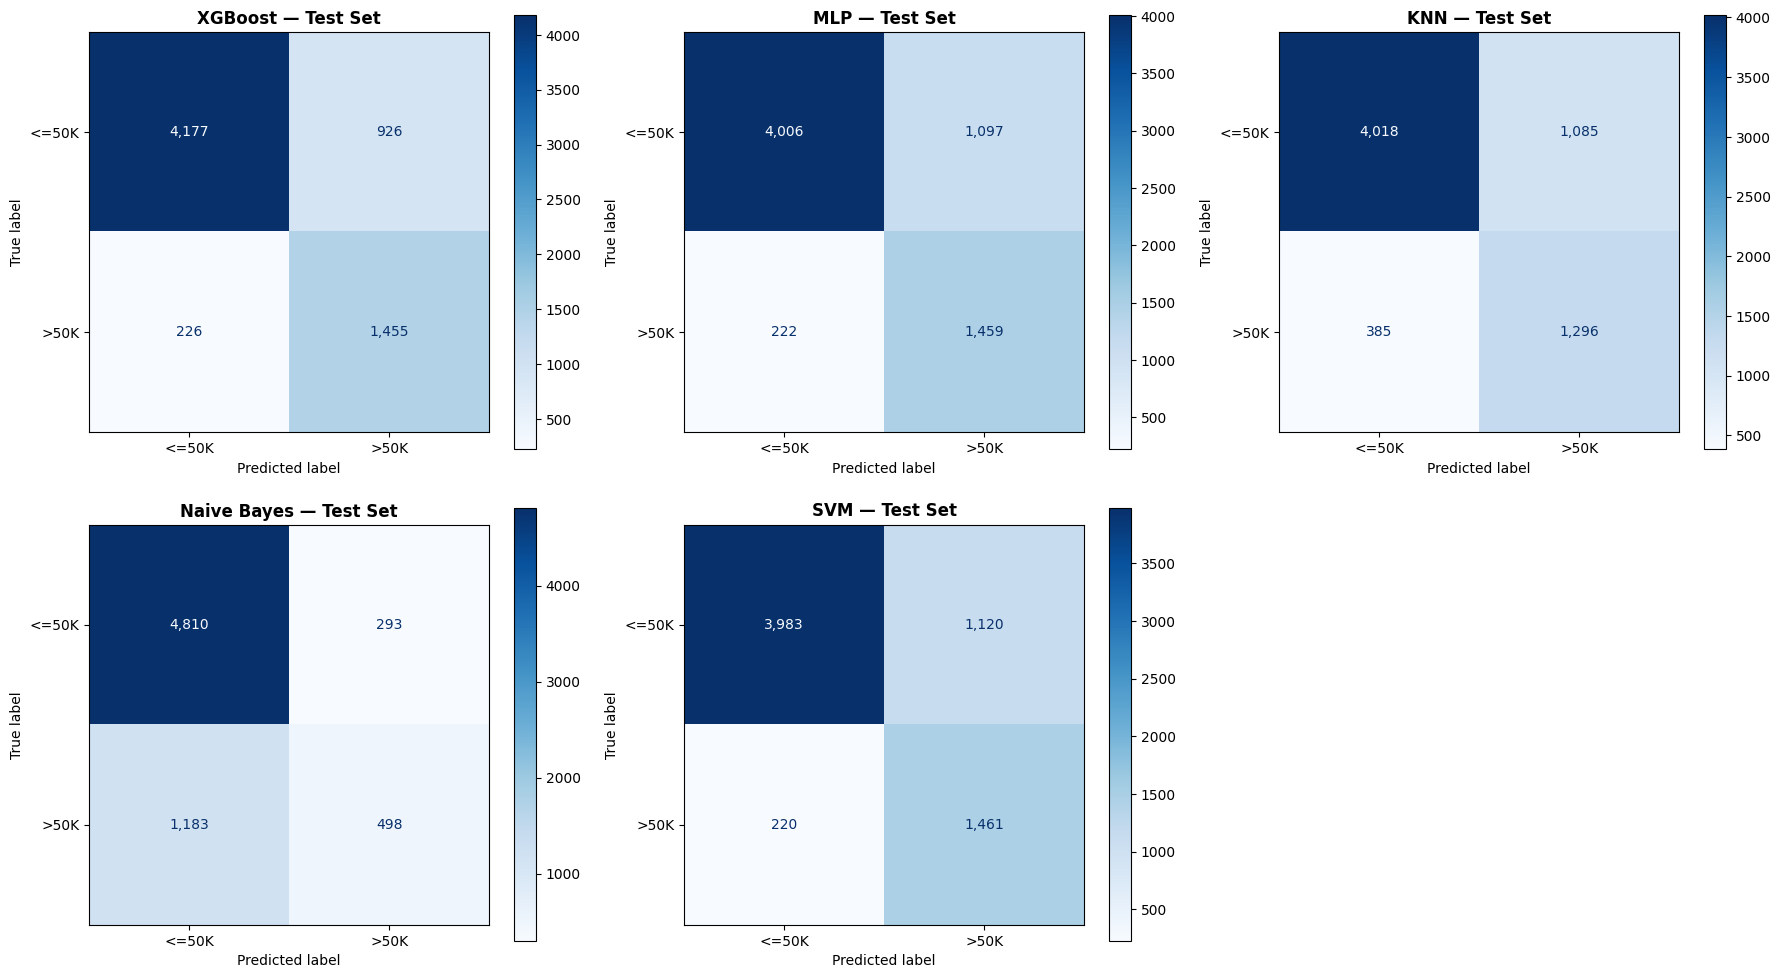

Confusion matrices saved to: /content/Model_result/all_models_test_confusion_matrices.png


In [ ]:
# Confusion Matrix của tất cả mô hình trên cùng Test Set.
model_names = list(test_predictions.keys())
n_models = len(model_names)
n_cols = 3
n_rows = (n_models + n_cols - 1) // n_cols
fig, axes = plt.subplots(n_rows, n_cols, figsize=(6 * n_cols, 5 * n_rows))
axes = np.asarray(axes).reshape(-1)

for ax, model_name in zip(axes, model_names):
    ConfusionMatrixDisplay.from_predictions(
        y_test, test_predictions[model_name]["y_pred"],
        labels=[0, 1], display_labels=["<=50K", ">50K"],
        cmap="Blues", values_format=",", ax=ax
    )
    ax.set_title(f"{model_name} — Test Set", fontsize=12, fontweight="bold")

for ax in axes[n_models:]:
    ax.set_visible(False)

fig.tight_layout()
output_path = RESULT_DIR / "all_models_test_confusion_matrices.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)
print(f"Confusion matrices saved to: {output_path.resolve()}")


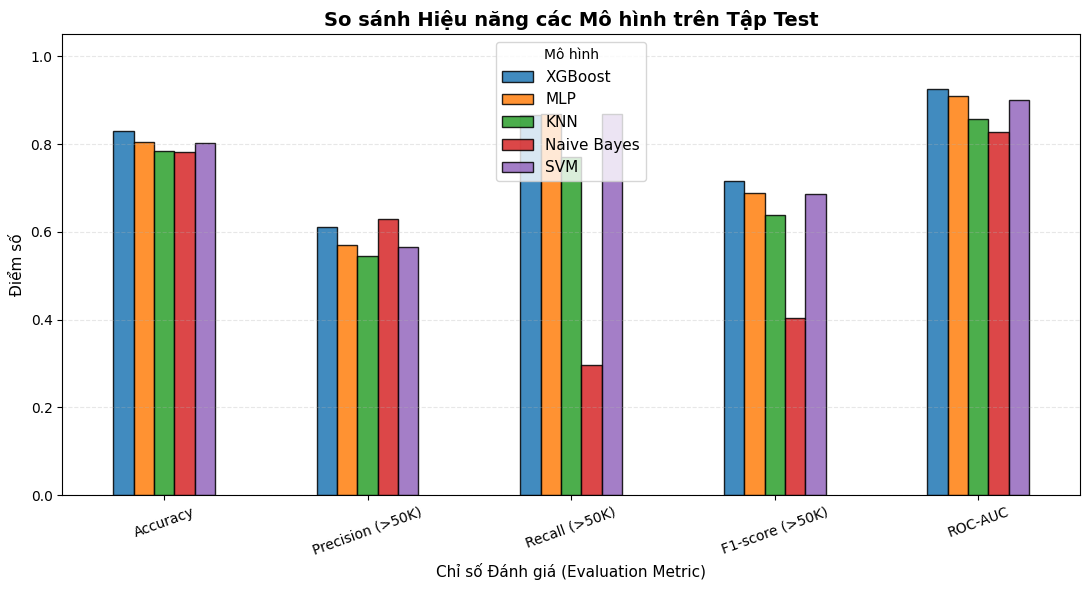

Chart saved to: /content/Model_result/all_models_test_metrics_comparison.png


In [ ]:
# Plot bar chart comparing key metrics between models
metrics_to_plot = [
    "Accuracy",
    "Precision (>50K)",
    "Recall (>50K)",
    "F1-score (>50K)",
    "ROC-AUC"
]

plot_data = test_comparison_results.set_index("Model")[metrics_to_plot]

ax = plot_data.T.plot(
    kind="bar",
    figsize=(11, 6),
    edgecolor="black",
    alpha=0.85
)

ax.set_title("So sánh Hiệu năng các Mô hình trên Tập Test", fontsize=14, fontweight="bold")
ax.set_xlabel("Chỉ số Đánh giá (Evaluation Metric)", fontsize=11)
ax.set_ylabel("Điểm số", fontsize=11)
ax.set_ylim(0, 1.05)
ax.tick_params(axis="x", rotation=20)
ax.grid(axis="y", linestyle="--", alpha=0.3)
ax.legend(title="Mô hình", fontsize=11)

fig = ax.get_figure()
fig.tight_layout()

output_path = RESULT_DIR / "all_models_test_metrics_comparison.png"
fig.savefig(output_path, dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)

print(f"Chart saved to: {output_path.resolve()}")


In [ ]:
import shutil
import zipfile
from pathlib import Path

# Result folders to bundle
folders_to_zip = [
    Path("EDA_result"),
    Path("Model_result")
]

existing_folders = [f for f in folders_to_zip if f.exists()]

if not existing_folders:
    print("Warning: No result folders found to archive.")
else:
    zip_filename = Path("Adult_Census_Income_Results.zip")
    with zipfile.ZipFile(zip_filename, "w", zipfile.ZIP_DEFLATED) as zipf:
        for folder in existing_folders:
            for file_path in folder.rglob("*"):
                if file_path.is_file():
                    zipf.write(file_path, file_path.as_posix())

    print(f"Tệp nén kết quả đã được tạo: {zip_filename.resolve()}")
    print(f"Kích thước file: {zip_filename.stat().st_size / 1024:.2f} KB")

# Support direct download in Google Colab
try:
    from google.colab import files
    files.download(str(zip_filename))
except ImportError:
    print("Not running in Google Colab. Download the ZIP file directly from your workspace.")


Tệp nén kết quả đã được tạo: /content/Adult_Census_Income_Results.zip
Kích thước file: 2047.71 KB


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>